In [1]:
import numpy as np
from transformers import AutoTokenizer, AutoModel
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import os

In [2]:
""" Loading data """
data = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")

In [3]:
data.head(5)

,date,category,headline,short_description,link,embedding
0,2012-01-28,ENTERTAINMENT,'Girl With the Dragon Tattoo' India Release Ca...,"""Sony Pictures will not be releasing The Girl ...",https://www.huffingtonpost.com/entry/girl-with...,"[0.263354182243347, -0.467815995216369, 0.0798..."
1,2012-01-28,PARENTING,With Friends Like These,I didn't appreciate the freedom of introducing...,https://www.huffingtonpost.com/entry/mom-frien...,"[0.48301681876182506, -0.766911804676055, -0.4..."
2,2012-01-28,PARENTING,Confession: This Pediatrician Is a Sleep Softie,This may not be a great confession to make as ...,https://www.huffingtonpost.com/entry/co-sleepi...,"[0.529987752437591, -0.220514968037605, -0.154..."
3,2012-01-28,ENTERTAINMENT,"Sundance, Ice-T, and Shades of the American Ra...",Representation of the collective diaspora has ...,https://www.huffingtonpost.com/entry/sundance-...,"[-0.15862986445426902, -0.40649029612541204, -..."
4,2012-01-28,PARENTING,Teen Responsibility Doesn't Happen -- It's Nur...,Do you feel kids today are as responsible as k...,https://www.huffingtonpost.com/entry/teaching-...,"[0.576590120792388, -0.539305448532104, 0.1647..."


In [4]:
""" To compute embeddings with ModernBERT """

def load_model(model_name="answerdotai/ModernBERT-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    return tokenizer, model

def get_embedding(text, tokenizer, model, device):
    """
    Generate embedding for a given text using ModernBERT.
    Uses mean pooling of the last hidden state.
    """
    # Tokenize and prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get embeddings
    with torch.no_grad():
        outputs = model(**inputs)
        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()

In [5]:
narratives_by_chapter = {
    "politics": {
        "trump": "Donald Trump will be elected because widespread economic discontent, distrust of political elites, and cultural backlash against globalization and immigration fuel support for an outsider candidate who promises disruption, national restoration, and direct confrontation with established institutions and media.",
        "obama": "Barack Obama will be re-elected because a slowly recovering economy, the successful framing of policy achievements such as healthcare reform, and strong coalition support among minorities, younger voters, and urban populations outweigh voter dissatisfaction and sustain confidence in incremental progress.",
        "obamacare": "The Affordable Care Act, often called Obamacare, is needed because it expands access to health insurance for millions of people who were previously uninsured or underinsured. The law aims to reduce healthcare costs over time, protect individuals with preexisting conditions, and strengthen the healthcare system by spreading risk more broadly across the population.",
    },
    "society": {
        "black_lives": "Black Lives Matter emerged as a movement responding to systemic racism, police violence, and unequal treatment of Black Americans within the criminal justice system. It connected individual incidents of violence to broader structural inequalities, using protests, social media, and cultural discourse to demand accountability, reform, and recognition of racial injustice in American society.",
        "shooting": "Mass shootings in the United States persist because of the widespread availability of firearms, gaps in mental health support, social isolation, media amplification of violence, and political gridlock that prevents comprehensive gun policy reform despite recurring public outrage.",
        "data_privacy": "Data privacy is important because personal information is increasingly collected, stored, and analyzed by governments and private companies, often without clear consent or transparency. Protecting data privacy helps preserve individual autonomy, prevents misuse and surveillance, and maintains trust in digital technologies that shape modern economic, social, and political life.",
        "paris_agreement": "The Paris Agreement is important because it represents a global commitment to limit climate change by reducing greenhouse gas emissions and promoting international cooperation. By setting shared goals and encouraging accountability, the agreement aims to mitigate the environmental, economic, and social risks associated with rising global temperatures and extreme weather events.",
        "school_shooting": "There are many ways to prevent school shootings because the issue involves multiple social, psychological, and policy factors. Approaches such as improving mental health support, enhancing school safety measures, fostering community engagement, and addressing access to firearms can collectively reduce the risk of violence.",
    },
    "geopolitics": {
        "ISIS": "ISIS attacks are happening because of prolonged instability in parts of the Middle East, power vacuums created by war, and sectarian divisions that extremist groups exploit. The organization uses violence and terrorism to assert control, spread fear, and gain international attention, while drawing recruits through ideological propaganda and grievances linked to political and economic marginalization.",
        "russia_crimea": "Russia is annexing Crimea because of strategic and political interests tied to regional influence, military access to the Black Sea, and concerns about Ukraine's alignment with Western institutions. The move follows political instability in Ukraine and is justified by Russian authorities as protecting ethnic Russians and national security, while being widely viewed internationally as a violation of Ukrainian sovereignty.",
        "brexit": "The United Kingdom votes to leave the European Union because of long-standing concerns about national sovereignty, immigration, and the perceived loss of democratic control to EU institutions. Economic uncertainty, regional inequality, and dissatisfaction with political elites also contribute to a referendum outcome driven by competing visions of globalization and national identity.",
    },
    "entertainment": {
        "game_of_thrones": "Game of Thrones is innovative because it combines cinematic production values with long-form television storytelling, complex characters, and morally ambiguous narratives. By subverting traditional fantasy tropes and embracing unpredictability, the series reshaped audience expectations and helped elevate television as a medium for ambitious, high-budget storytelling.",
        "me_too": "The Me Too movement is a revolution because it fundamentally changes how sexual harassment and abuse are discussed, exposing systemic power imbalances across industries. By amplifying personal testimony and collective accountability, the movement challenges long-standing norms of silence and reshapes cultural and institutional responses to misconduct.",
        "stream_music": "Streaming-first music releases are changing the industry because they shift power away from traditional distribution models toward digital platforms and data-driven consumption. This approach alters how artists release, promote, and monetize music, emphasizing continuous engagement, algorithmic visibility, and global accessibility over physical sales and scheduled releases.",
    },
    "travel": {
        "MH370": "The disappearance of Malaysia Airlines Flight MH370 is terrible because it represents a profound human tragedy marked by uncertainty, loss, and unanswered questions. The incident exposed vulnerabilities in global aviation tracking and left families and the international community without clear explanations or closure.",
        "airlines": "Airlines push premium economy seating and loyalty-program changes because they seek to increase revenue in a highly competitive industry facing rising costs and thin margins. By segmenting passengers and monetizing comfort and perks, airlines aim to maximize profits while adapting to changing traveler expectations and spending behavior.",
        "rentals": "Cities begin regulating short-term rentals because rapid growth of platforms like Airbnb affects housing availability, neighborhood stability, and local infrastructure. Policymakers respond to concerns about rising rents, tourism pressure, and fairness between traditional hotels and peer-to-peer accommodations.",
        "ebola": "Ebola is dangerous because it is a highly contagious and often fatal disease that can spread rapidly in areas with limited healthcare infrastructure. Outbreaks generate fear, disrupt travel and economies, and highlight global vulnerabilities in disease detection, containment, and public health preparedness.",
    },
    "parenting": {
        "same_sex": "Same-sex marriage is a revolution because it fundamentally reshapes legal definitions of family, equality, and civil rights. By extending marriage protections to LGBTQ+ couples, it challenges long-standing social norms and affirms the principle that legal recognition should not depend on sexual orientation.",
        "parental_leave": "Paid parental leave is a change because it redefines the relationship between work, family, and economic security. By allowing parents time to care for newborns without losing income or employment, it shifts expectations about caregiving responsibilities and workplace support for families.",
        "screen_time": "Screen time for teens is dangerous because excessive use of digital devices can affect mental health, sleep patterns, and social development. Constant exposure to social media and online comparison may increase anxiety, reduce attention, and shape behavior during a critical stage of emotional growth.",
    },
}

In [6]:
chapter_names = list(narratives_by_chapter.keys())

In [7]:
""" Orthogonality computation """
def solve_orthogonal_narratives(N, n_restarts=10, max_iter=100, tol=1e-8):
    """
    Solves max min_i <N_i, V_i>  s.c. V_i ⊥ V_j, ||V_i|| = 1
    """
    extra_Ni = np.random.randn(N.shape[1])
    N = np.vstack([extra_Ni, N])
    n, d = N.shape
    best_V, best_score = None, -np.inf



    for restart in range(n_restarts):
        perm = np.random.permutation(n)  # Ensure the extra vector is first
        V = np.zeros((n, d))

        for idx, i in enumerate(perm):
            v = N[i].copy()
            for j in perm[:idx]:
                v -= np.dot(v, V[j]) * V[j]
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        prev_score = -np.inf
        for _ in range(max_iter):
            for i in range(n):
                proj = V.T @ (V @ N[i])
                v = N[i] - proj + V[i] * np.dot(V[i], N[i])
                norm = np.linalg.norm(v)
                if norm > 1e-10:
                    V[i] = v / norm
                if np.dot(N[i], V[i]) < 0:
                    V[i] *= -1

            score = min(np.dot(N[i], V[i]) for i in range(n))
            if score - prev_score < tol:
                break
            prev_score = score

        if score > best_score:
            best_V, best_score = V.copy(), score

    return best_V[1:], best_score

In [8]:
""" Compute narratives embeddings and solve orthogonality problem """
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
model = AutoModel.from_pretrained("answerdotai/ModernBERT-base").to(device)
model.eval()

rows = []
for chapter, narratives in narratives_by_chapter.items():
    for title, text in narratives.items():
        rows.append({"chapter": chapter, "title": title, "text": text})

N = np.array([get_embedding(row["text"], tokenizer, model, device) for row in rows])
V, score = solve_orthogonal_narratives(N, n_restarts=20)

N_minus_V = N - V

/users/eleves-b/2023/juliette.anglade/Desktop/Code/myenv/lib64/python3.9/site-packages/networkx/utils/backends.py:135: RuntimeWarning: networkx backend defined more than once: nx-loopback
  backends.update(_get_backends("networkx.backends"))
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disablin

In [9]:
narratives = pd.DataFrame([{**rows[i], "embedding": N[i]} for i in range(len(rows))])
narratives_orth = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_orth", "text": rows[i]["text"], "embedding": V[i]} for i in range(len(rows))])
narratives_complementary = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_comple", "text": rows[i]["text"], "embedding": N_minus_V[i]} for i in range(len(rows))])

narratives.to_csv("./data_narratives/narratives.csv", index=False)
narratives_orth.to_csv("./data_narratives/narratives_orth.csv", index=False)
narratives_complementary.to_csv("./data_narratives/narratives_complementary.csv", index=False)

print("Sauvegardé : narratives.csv")
print("Sauvegardé : narratives_orth.csv")

Sauvegardé : narratives.csv
Sauvegardé : narratives_orth.csv


In [10]:
narrative_names = (narratives.chapter + ':' + narratives.title).to_list()
narrative_matrix = np.array(narratives['embedding'].to_list())

orthogonal_names = (narratives_orth.chapter + ':' + narratives_orth.title).to_list()
orthogonal_matrix = np.array(narratives_orth['embedding'].to_list())

complementary_names = (narratives_complementary.chapter + ':' + narratives_complementary.title).to_list()
complementary_matrix = np.array(narratives_complementary['embedding'].to_list())

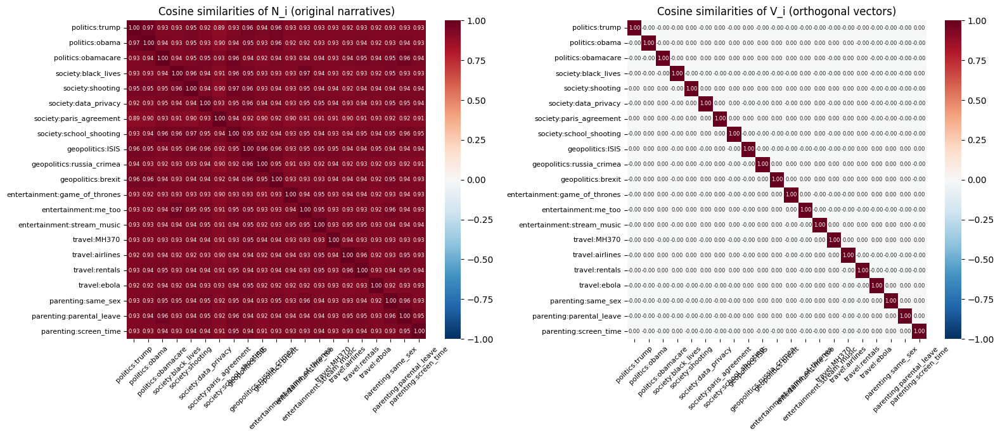

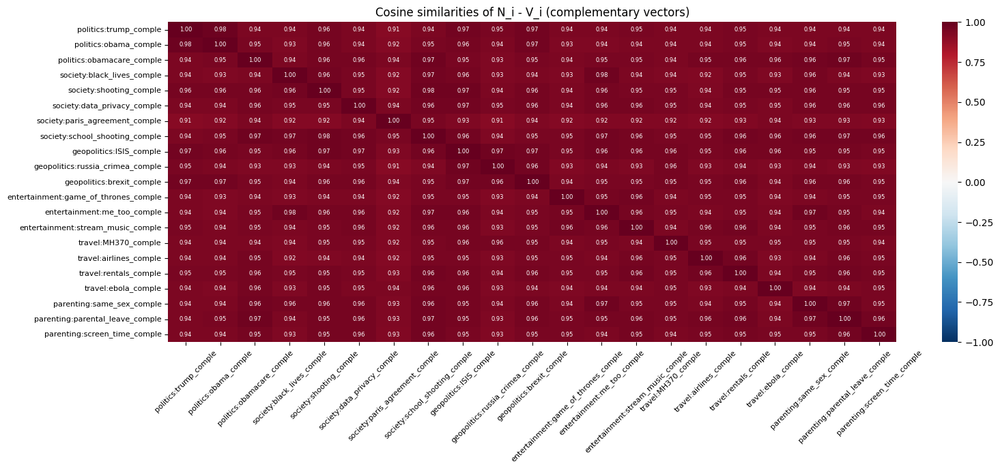

In [11]:
cos_sim_narratives = cosine_similarity(narrative_matrix)
cos_sim_orth = cosine_similarity(orthogonal_matrix)
cos_sim_comp = cosine_similarity(complementary_matrix)

cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, orthogonal_matrix, complementary_matrix]))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Heatmap for original narratives N_i
sns.heatmap(
    cos_sim_narratives,
    ax=axes[0],
    xticklabels=narrative_names,
    yticklabels=narrative_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes[0].set_title('Cosine similarities of N_i (original narratives)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].tick_params(axis='y', rotation=0, labelsize=8)

# Heatmap for orthogonal vectors V_i
sns.heatmap(
    cos_sim_orth,
    ax=axes[1],
    xticklabels=narrative_names,
    yticklabels=narrative_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes[1].set_title('Cosine similarities of V_i (orthogonal vectors)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1].tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig('cosine_similarities.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 1, figsize=(16, 7))
# Heatmap for complementary vectors N_i - V_i
sns.heatmap(
    cos_sim_comp,
    xticklabels=complementary_names,
    yticklabels=complementary_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of N_i - V_i (complementary vectors)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

    
plt.tight_layout()
plt.savefig('cosine_similarities.png', dpi=150, bbox_inches='tight')
plt.show()

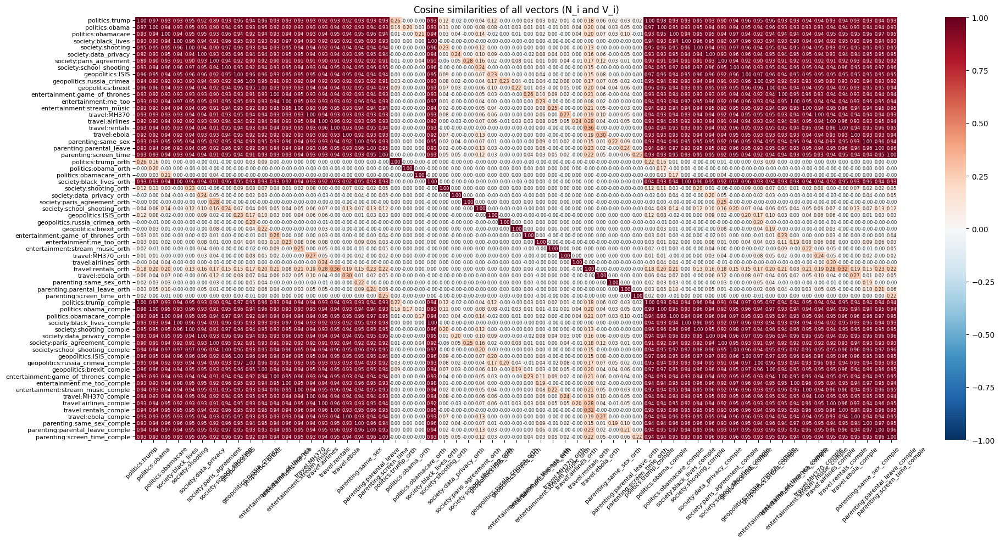

In [12]:
fig, axes = plt.subplots(1, 1, figsize=(20, 10))
# Heatmap for all vectors N_i and V_i, N_i - V_i
sns.heatmap(
    cosine_sim_all,
    xticklabels=narrative_names + orthogonal_names + complementary_names,
    yticklabels=narrative_names + orthogonal_names + complementary_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig('cosine_similarities_all.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
"""Create dataframe with the cosine similarity with orthogonal narratives"""
from tqdm.notebook import tqdm
from sklearn.metrics.pairwise import cosine_similarity

print("Computing cosine similarities with narratives and orthogonal narratives...")


time_series_data = []
gdir = './data_narratives'

for idx, row in tqdm(data.iterrows(), total=len(data)):
    # Get article embedding
    article_embedding = row['embedding']
    if isinstance(article_embedding, list):
        article_embedding = np.array(article_embedding)
    
    info_similarities = {
        'date': row['date'],
        'category': row['category'],
        'headline': row['headline'],
        'link': row.get('link', '')
    }
    
    # Compute cosine similarities with narratives (vectorized)
    similarities_narratives = cosine_similarity(
        article_embedding.reshape(1, -1),
        narrative_matrix
    )[0]
    
    for name, sim in zip(narrative_names, similarities_narratives):
        info_similarities[f"{name}"] = float(sim)
    
    # Compute cosine similarities with orthogonal narratives (vectorized)
    similarities_orthogonal = cosine_similarity(
        article_embedding.reshape(1, -1),
        orthogonal_matrix
    )[0]
    
    for name, sim in zip(orthogonal_names, similarities_orthogonal):
        info_similarities[f"{name}"] = float(sim)

    time_series_data.append(info_similarities)

# Save to CSV
ts_df = pd.DataFrame(time_series_data)
filepath = os.path.join(gdir, 'narrative_exposures_with_orthogonal.csv')
os.makedirs(gdir, exist_ok=True)
ts_df.to_csv(filepath, index=False)
print(f"✓ Saved to: {filepath}")
print(f"Shape: {ts_df.shape}")
print(f"Columns: {ts_df.columns.tolist()[:10]}...")  # Show first 10 columns

Computing cosine similarities with narratives and orthogonal narratives...


  0%|          | 0/67361 [00:00<?, ?it/s]

✓ Saved to: ./data_narratives/narrative_exposures_with_orthogonal.csv
Shape: (67361, 46)
Columns: ['date', 'category', 'headline', 'link', 'politics:trump', 'politics:obama', 'politics:obamacare', 'society:black_lives', 'society:shooting', 'society:data_privacy']...


In [14]:
ts_df.sample(10)

,date,category,headline,link,politics:trump,politics:obama,politics:obamacare,society:black_lives,society:shooting,society:data_privacy,...,entertainment:game_of_thrones_orth,entertainment:me_too_orth,entertainment:stream_music_orth,travel:MH370_orth,travel:airlines_orth,travel:rentals_orth,travel:ebola_orth,parenting:same_sex_orth,parenting:parental_leave_orth,parenting:screen_time_orth
28627,2015-07-14,ENTERTAINMENT,'Star Wars' GoPro Video Shows What It's Like T...,https://www.huffingtonpost.com/entry/star-wars...,0.897439,0.896811,0.902408,0.893448,0.898750,0.901386,...,0.061872,0.099196,0.016928,0.100881,0.010872,0.234868,0.069395,0.036463,0.067475,0.015944
34299,2015-12-24,ENTERTAINMENT,Chrissy Teigen And John Legend Are Having A Girl!,https://www.huffingtonpost.com/entry/chrissy-t...,0.820150,0.814063,0.837164,0.818558,0.820343,0.820584,...,0.067766,0.093424,0.054050,0.043998,-0.017894,0.252166,0.056704,0.046695,0.087129,0.001817
9140,2013-04-01,TRAVEL,5 Awesome Los Angeles Beaches for Families,https://www.huffingtonpost.com/entry/los-angel...,0.910761,0.917694,0.928655,0.912565,0.917431,0.916221,...,0.055573,0.063264,0.006586,0.043514,0.009177,0.259796,0.047824,0.029213,0.061119,-0.000524
63189,2018-01-19,ENTERTAINMENT,Jean-Claude Van Damme Explains Why His Ball-Pu...,https://www.huffingtonpost.com/entry/jean-clau...,0.900244,0.900593,0.912820,0.897313,0.901162,0.902920,...,0.069842,0.097841,0.043661,0.073848,0.011053,0.239985,0.050632,0.048979,0.083827,0.024496
2578,2012-06-14,TRAVEL,Cars Land Debuts At Disney's California Advent...,https://www.huffingtonpost.com/entry/cars-land...,0.906041,0.905515,0.905751,0.889627,0.897949,0.889968,...,0.064197,0.075418,0.040004,0.070518,0.023502,0.251652,0.068946,0.054055,0.076488,0.017241
7950,2013-02-12,TRAVEL,"Best Day Ever: Turtle Inn, Belize",https://www.huffingtonpost.comhttp://fathomawa...,0.886987,0.887544,0.886791,0.871882,0.879790,0.883323,...,0.031917,0.063420,0.033089,0.074520,-0.038481,0.253243,0.082170,0.031201,0.076913,0.029417
24657,2015-01-28,POLITICS,This Is The Plane That Will Be The New Air For...,https://www.huffingtonpost.com/entry/new-air-f...,0.814048,0.812656,0.835636,0.819827,0.823147,0.814152,...,0.058410,0.067632,0.033670,0.102602,-0.011978,0.240706,0.062150,0.028247,0.045224,-0.012521
20214,2014-07-18,POLITICS,"Good News For Clinton, Huckabee",https://www.huffingtonpost.com/entry/good-news...,0.864148,0.852869,0.845014,0.834153,0.840690,0.828293,...,0.046987,0.071542,0.034307,0.067826,-0.021297,0.220618,0.058833,0.042416,0.086140,0.021343
64612,2018-03-03,POLITICS,Trump's Tariff Can't Start A Trade War Because...,https://www.huffingtonpost.com/entry/trump-tra...,0.897971,0.887666,0.902744,0.883540,0.883821,0.880438,...,0.040998,0.085944,0.003928,0.063075,-0.002608,0.230352,0.077677,0.046836,0.074626,-0.001709
17177,2014-03-07,PARENTING,"He Said, 'I Think Your Baby Has Dwarfism'",https://www.huffingtonpost.com/entry/he-said-i...,0.908945,0.914517,0.934138,0.907373,0.913572,0.912484,...,0.052476,0.087826,0.023851,0.062633,0.007781,0.229585,0.047891,0.039461,0.094434,0.029815


In [15]:
gdir = './data_narratives'

# Check if file exists
filepath = os.path.join(gdir, 'narrative_exposures_with_orthogonal.csv')
if os.path.exists(filepath):
    ts2_df = pd.read_csv(filepath)
    print(f"Loaded narrative_exposures_df from: {filepath}")
    print(f"Shape: {ts2_df.shape}")
    ts2_df.sample(3)
else:
    print(f"File not found: {filepath}")
    print(f"Available files in {gdir}:")
    if os.path.exists(gdir):
        print(os.listdir(gdir))
    else:
        print(f"Directory {gdir} does not exist")

Loaded narrative_exposures_df from: ./data_narratives/narrative_exposures_with_orthogonal.csv
Shape: (67361, 46)


In [16]:
ts_df = ts2_df.copy()

In [17]:
def explode_colgroup(colgroup):
  group_cols = {}
  for oc in colgroup:
    g, c = oc.split(':')
    gc = group_cols.get(g, []) + [oc]
    group_cols[g] = gc
  print(f"{len(group_cols)} groups")
  return group_cols



['politics:trump', 'politics:obama', 'politics:obamacare']


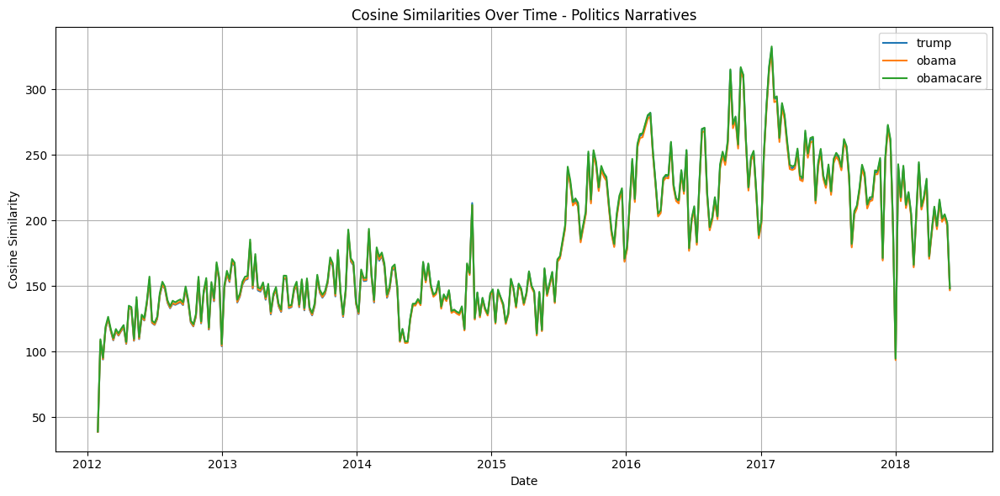

['society:black_lives', 'society:shooting', 'society:data_privacy', 'society:paris_agreement', 'society:school_shooting']


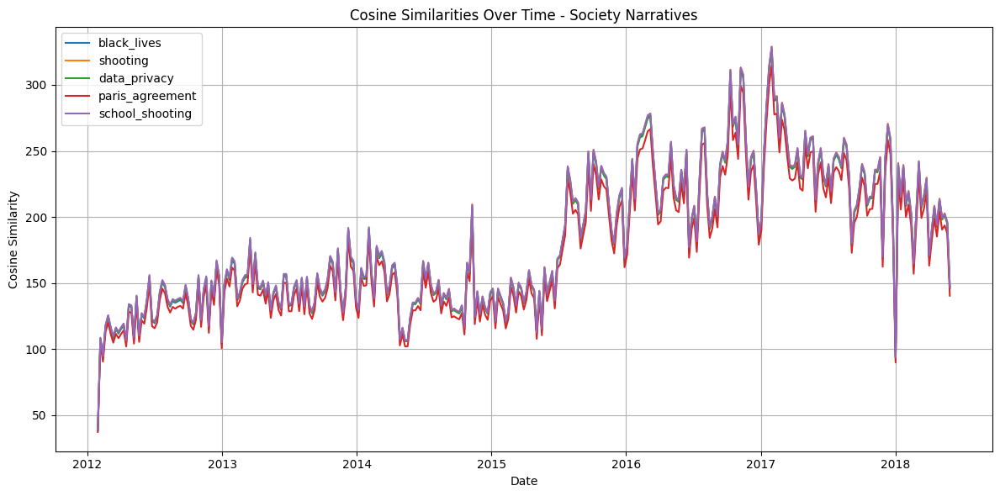

['geopolitics:ISIS', 'geopolitics:russia_crimea', 'geopolitics:brexit']


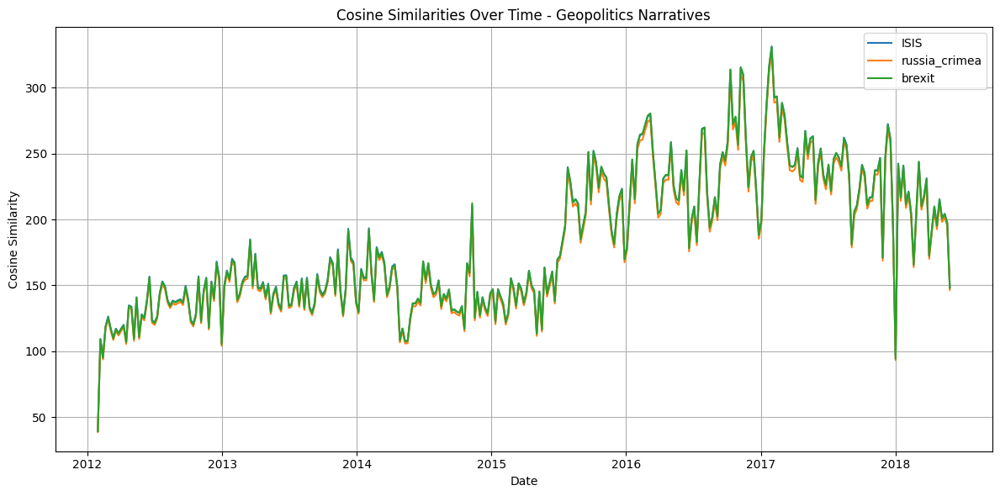

['entertainment:game_of_thrones', 'entertainment:me_too', 'entertainment:stream_music']


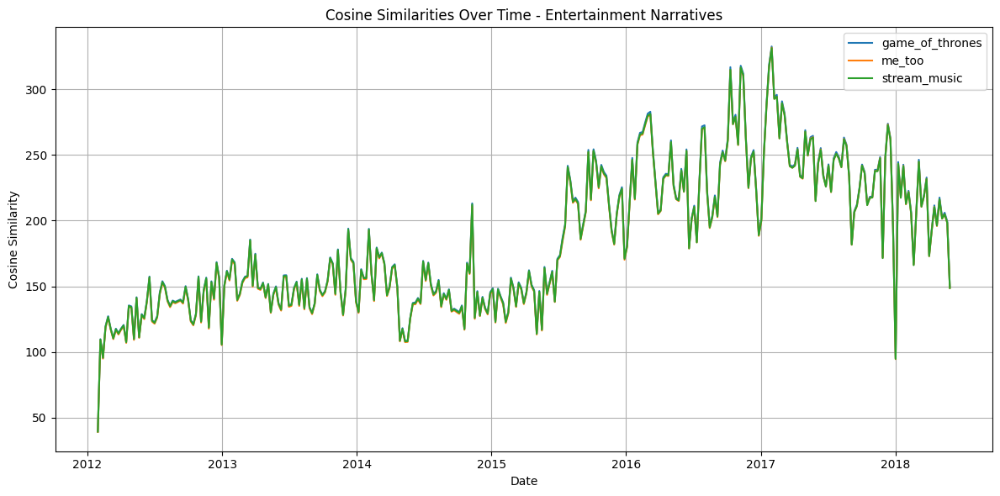

['travel:MH370', 'travel:airlines', 'travel:rentals', 'travel:ebola']


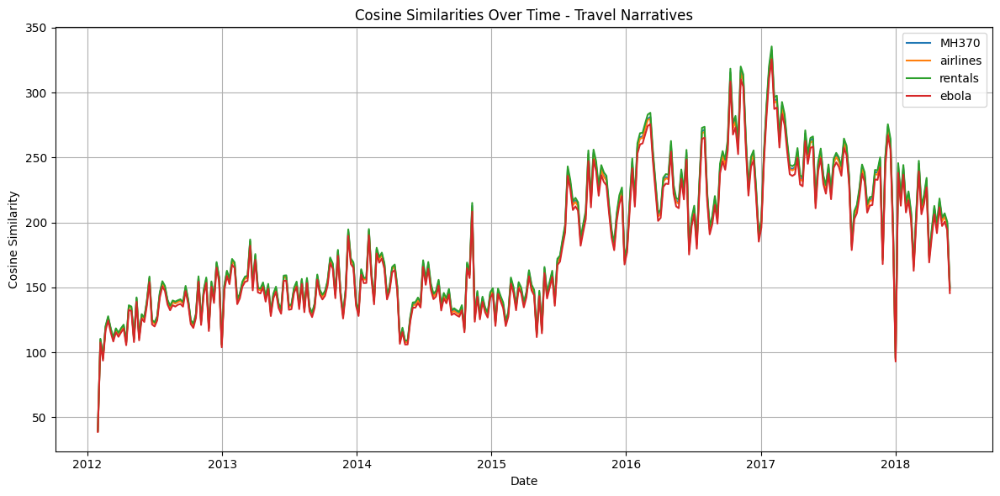

['parenting:same_sex', 'parenting:parental_leave', 'parenting:screen_time']


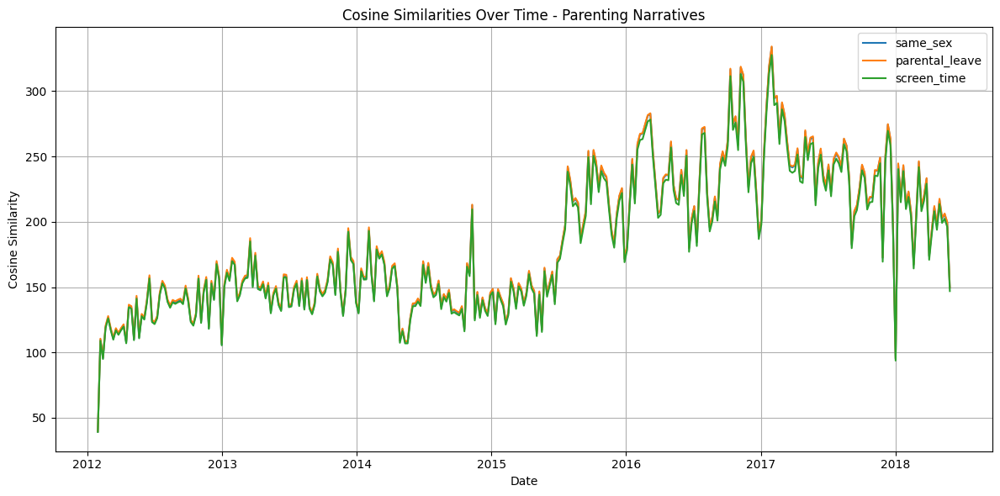

In [18]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

""" Visualization of cosine time series for original narratives"""

for chapter in chapter_names:
    chapter_narrative_cols = [col for col in narrative_cols if col.startswith(chapter + ':')]
    print(chapter_narrative_cols)
    plt.figure(figsize=(12, 6))
    for col in chapter_narrative_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        plt.plot(dates, cosine_similarities, label=col.split(':')[1])
    plt.title(f'Cosine Similarities Over Time - {chapter.capitalize()} Narratives')
    plt.xlabel('Date')
    plt.ylabel('Cosine Similarity')
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()



['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


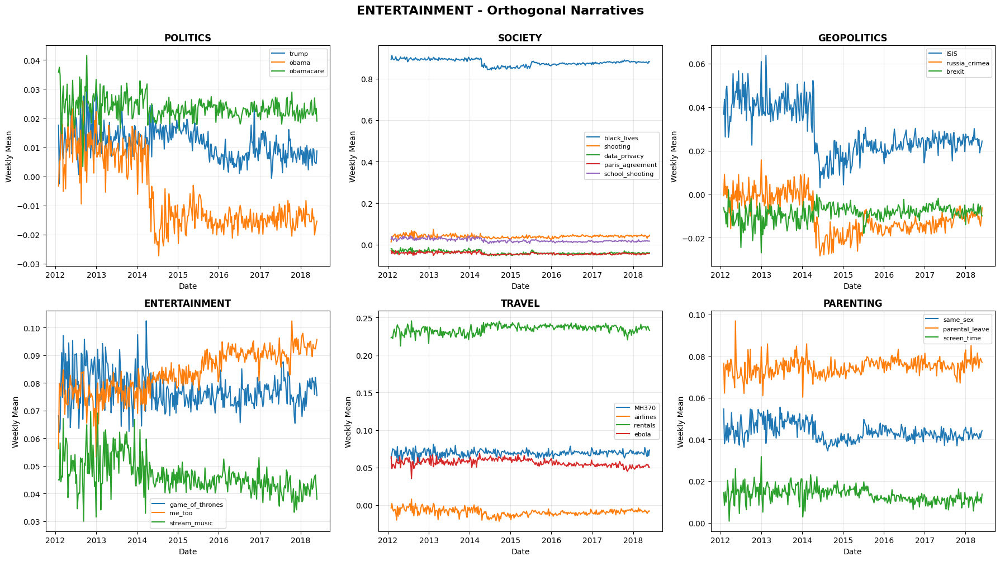

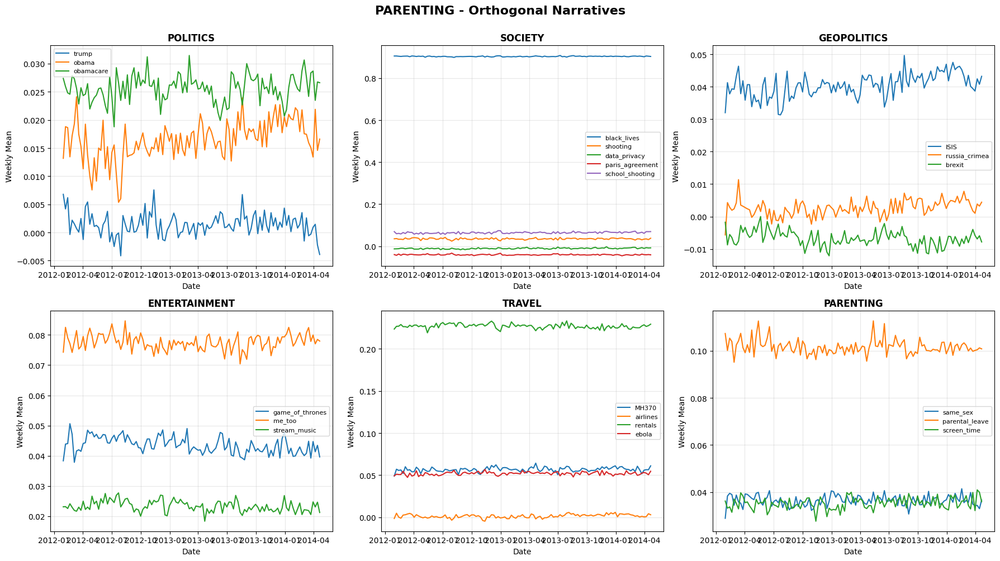

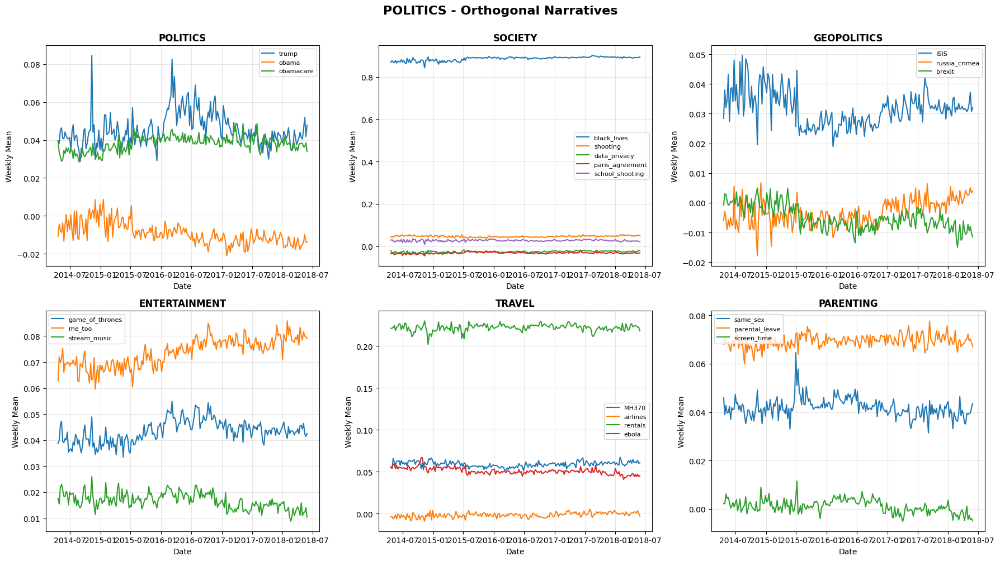

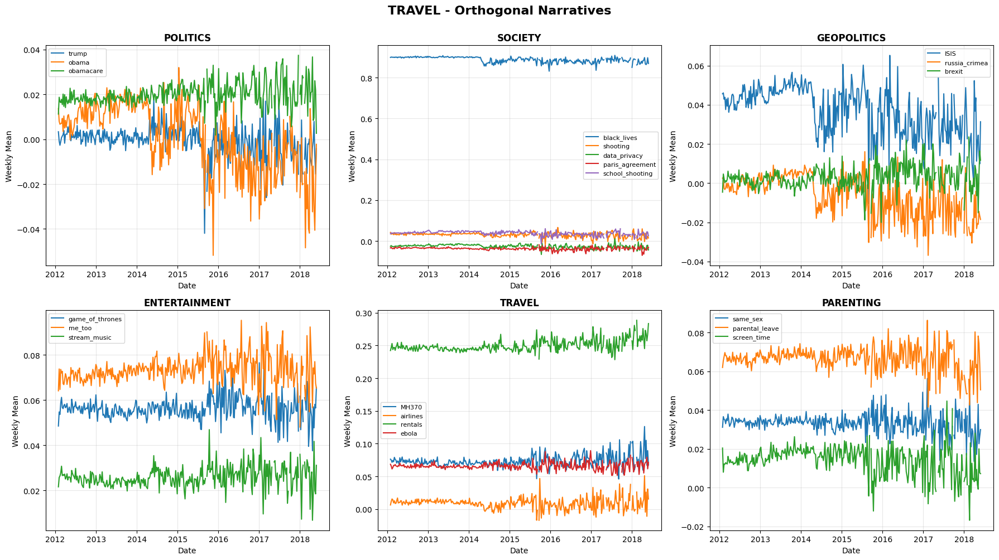

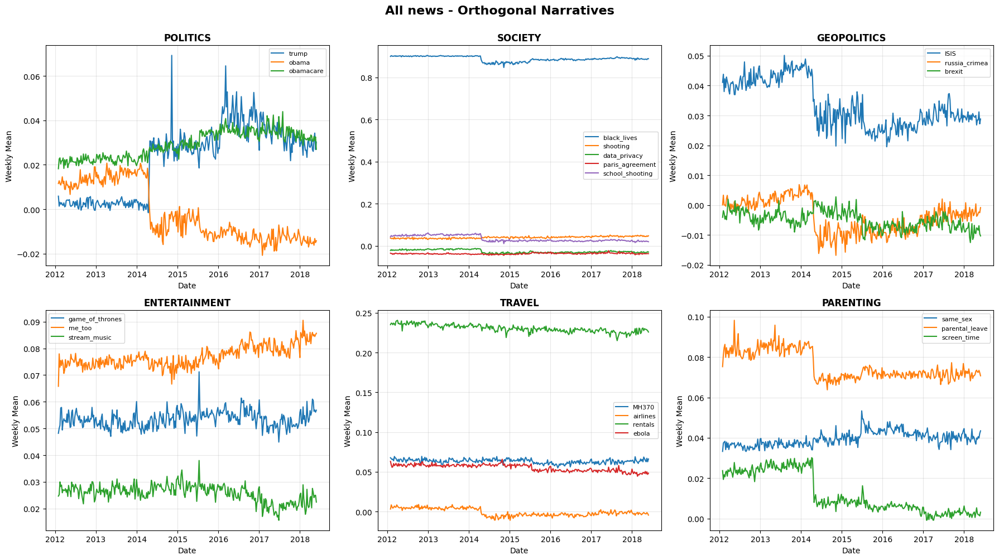

In [19]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique()) 
print(news_categories)

""" Visualization of cosine time series for ORTHOGONAL narratives - GROUPED BY NEWS CATEGORY """

for news_cat in news_categories:
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create subplots: one per chapter (6 chapters)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for ax_idx, chapter in enumerate(chapter_names):
        chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
        if not chapter_orthogonal_cols:
            axes[ax_idx].set_visible(False)
            continue
        
        for col in chapter_orthogonal_cols:
            cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
            dates = cosine_similarities.index
            narrative_name = col.split(':')[1].replace('_orth', '')
            axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Mean', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
    if not chapter_orthogonal_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Mean', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


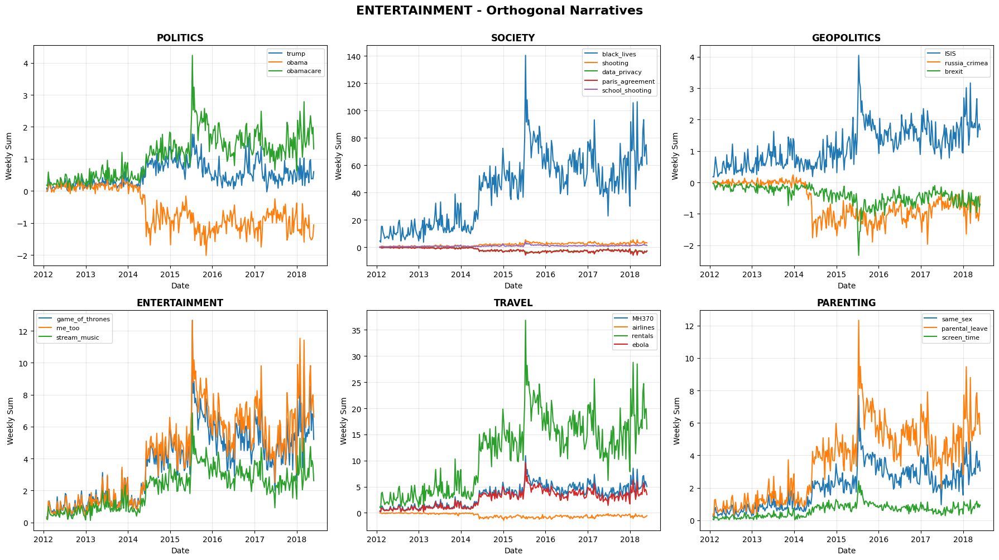

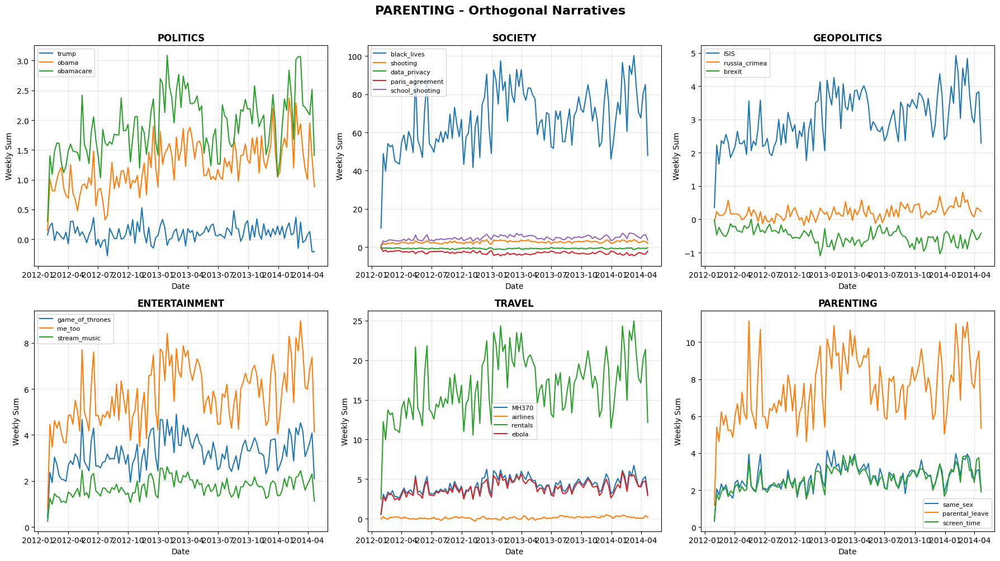

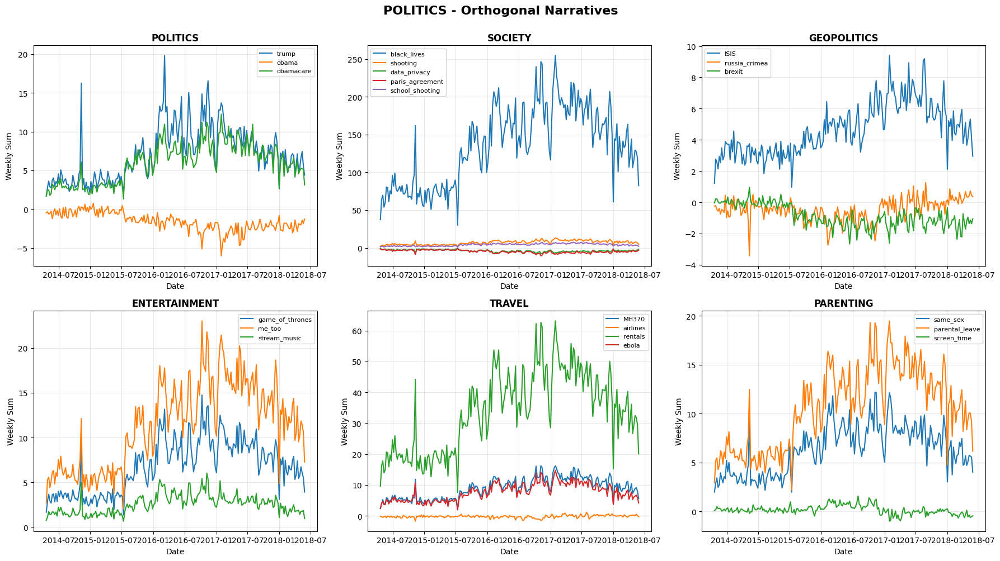

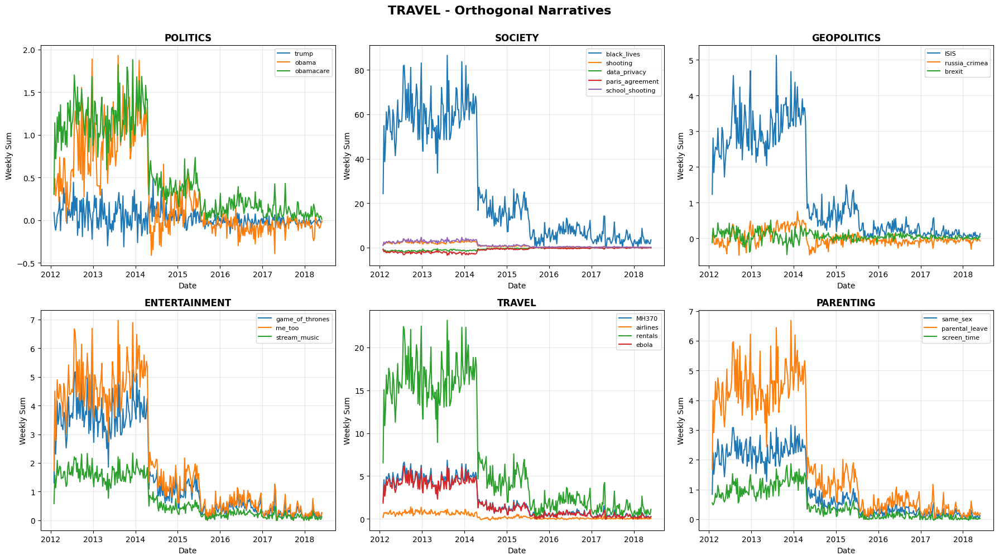

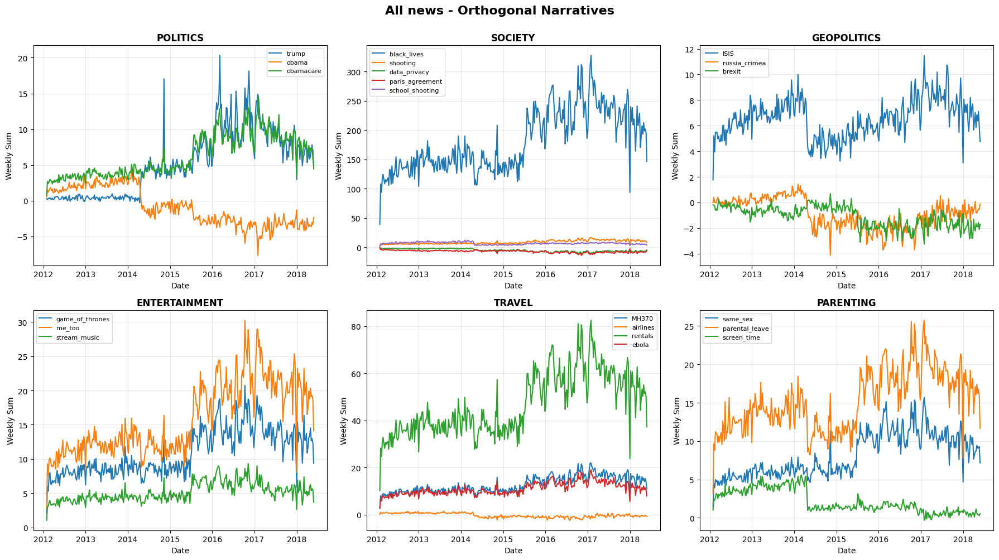

In [20]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique()) 
print(news_categories)

""" Visualization of cosine time series for ORTHOGONAL narratives - GROUPED BY NEWS CATEGORY """

for news_cat in news_categories:
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create subplots: one per chapter (6 chapters)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for ax_idx, chapter in enumerate(chapter_names):
        chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
        if not chapter_orthogonal_cols:
            axes[ax_idx].set_visible(False)
            continue
        
        for col in chapter_orthogonal_cols:
            cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
            dates = cosine_similarities.index
            narrative_name = col.split(':')[1].replace('_orth', '')
            axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
    if not chapter_orthogonal_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


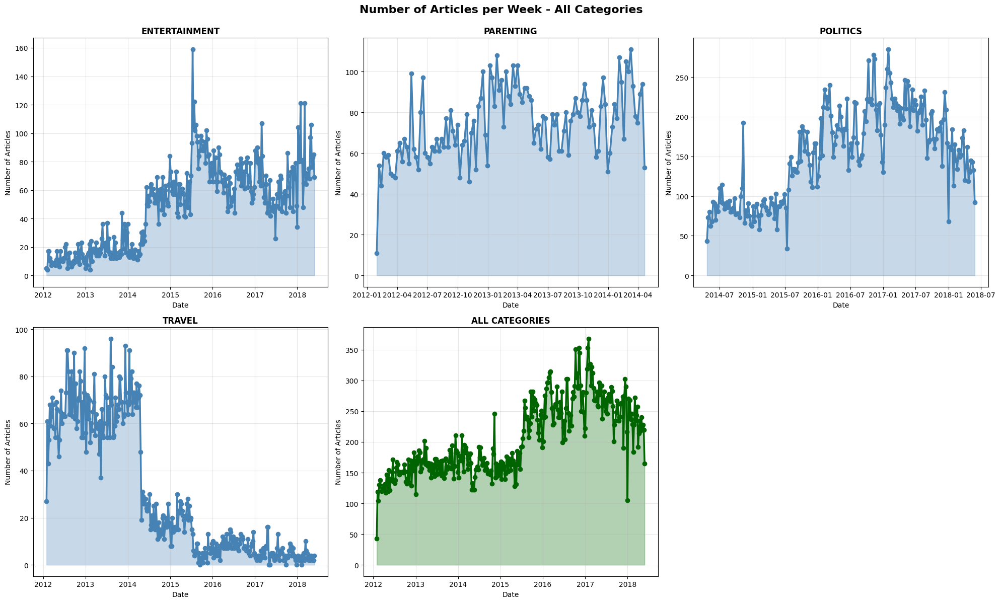

In [21]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

""" Visualization of number of articles per week - ALL GRAPHS SIDE BY SIDE """

# Create a large figure with subplots: 2 rows x 3 columns
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

# Plot one graph per category
for idx, news_cat in enumerate(news_categories):
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    articles_per_week = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON')).size()
    
    dates = articles_per_week.index
    counts = articles_per_week.values
    
    axes[idx].plot(dates, counts, linewidth=2.5, marker='o', color='steelblue')
    axes[idx].fill_between(dates, counts, alpha=0.3, color='steelblue')
    axes[idx].set_title(f'{news_cat.upper()}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Date', fontsize=10)
    axes[idx].set_ylabel('Number of Articles', fontsize=10)
    axes[idx].grid(True, alpha=0.3)

# Plot ALL NEWS in the last subplot
articles_per_week_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON')).size()
dates_all = articles_per_week_all.index
counts_all = articles_per_week_all.values

axes[4].plot(dates_all, counts_all, linewidth=2.5, marker='o', color='darkgreen')
axes[4].fill_between(dates_all, counts_all, alpha=0.3, color='darkgreen')
axes[4].set_title('ALL CATEGORIES', fontsize=12, fontweight='bold')
axes[4].set_xlabel('Date', fontsize=10)
axes[4].set_ylabel('Number of Articles', fontsize=10)
axes[4].grid(True, alpha=0.3)

# Hide the 6th subplot (unused)
axes[5].set_visible(False)

fig.suptitle('Number of Articles per Week - All Categories', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

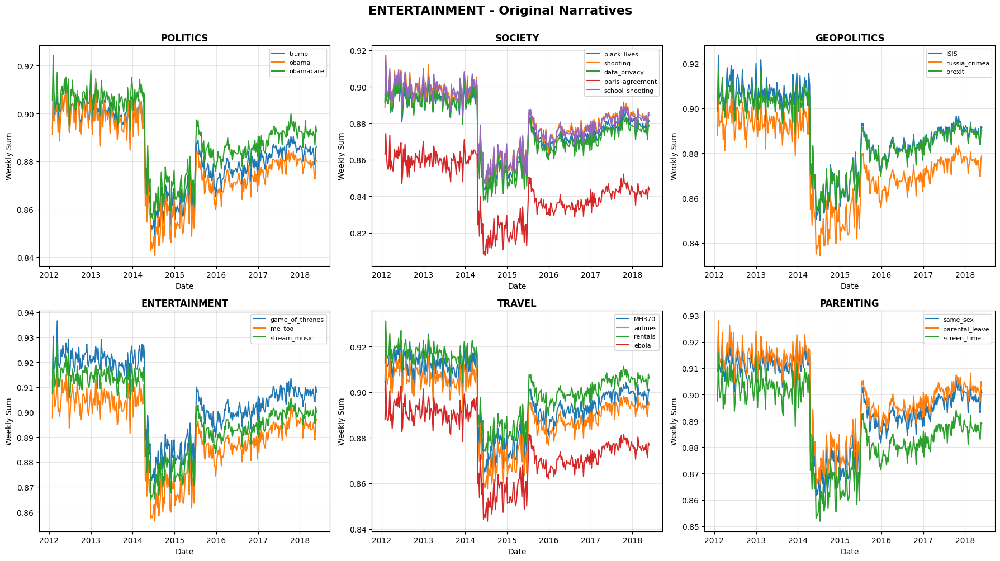

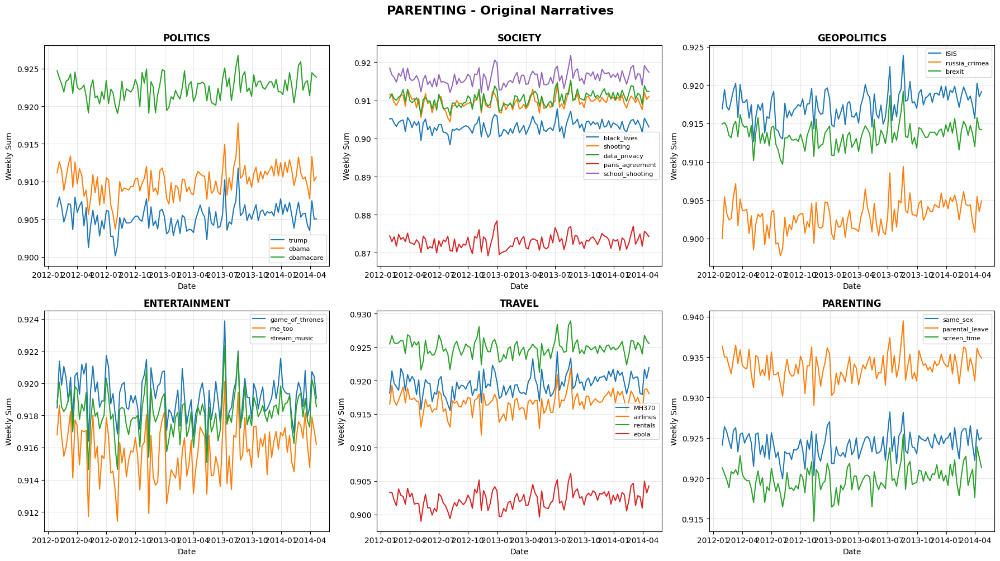

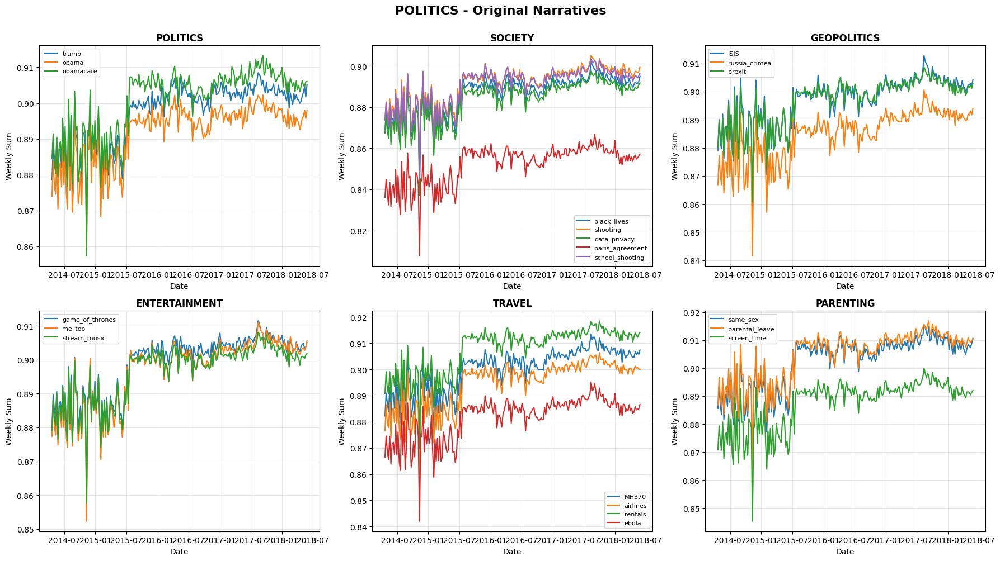

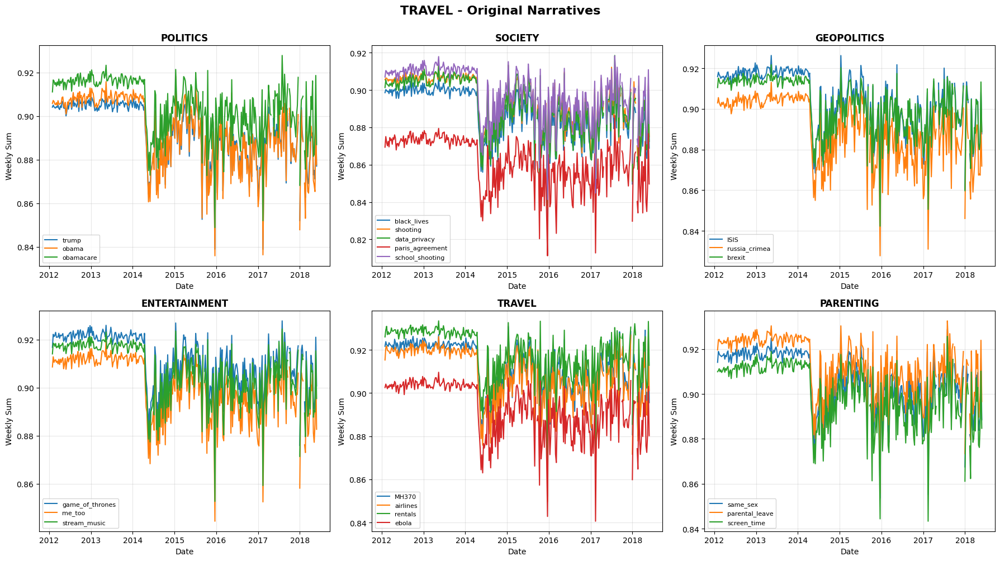

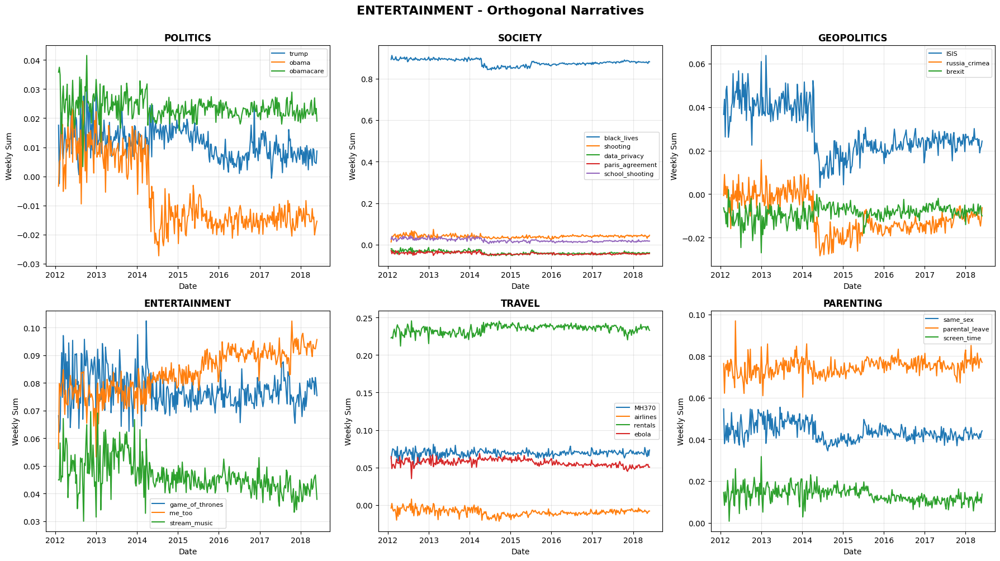

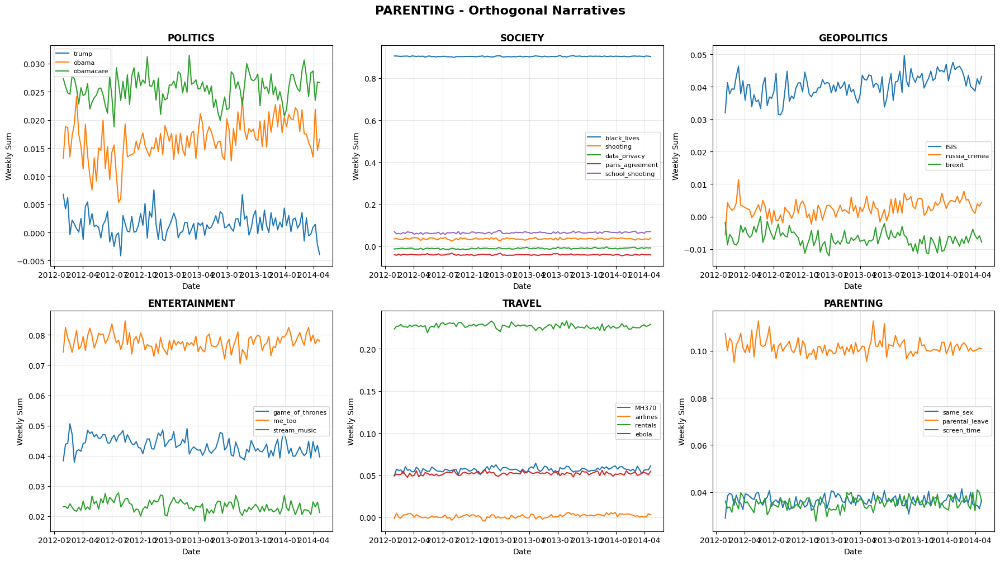

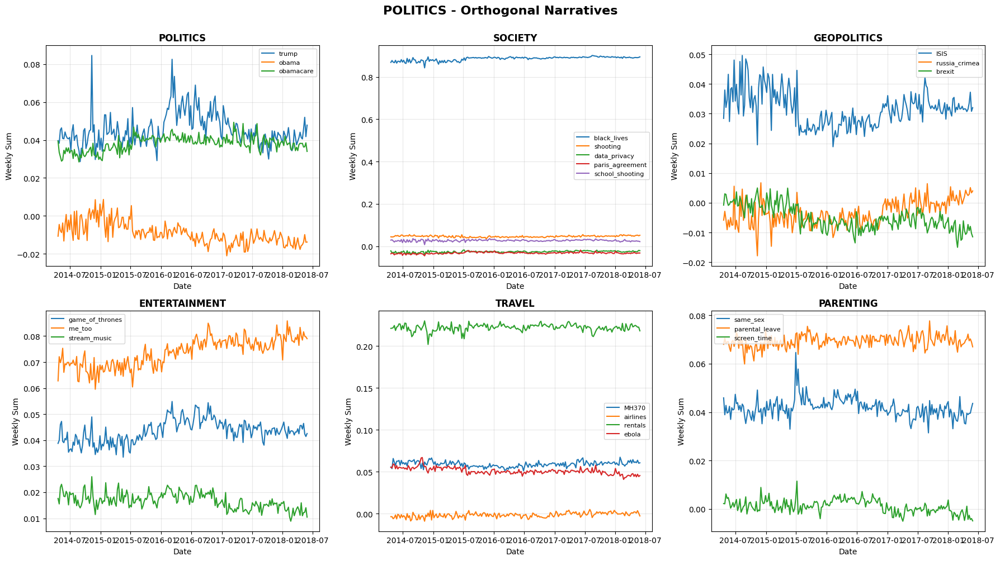

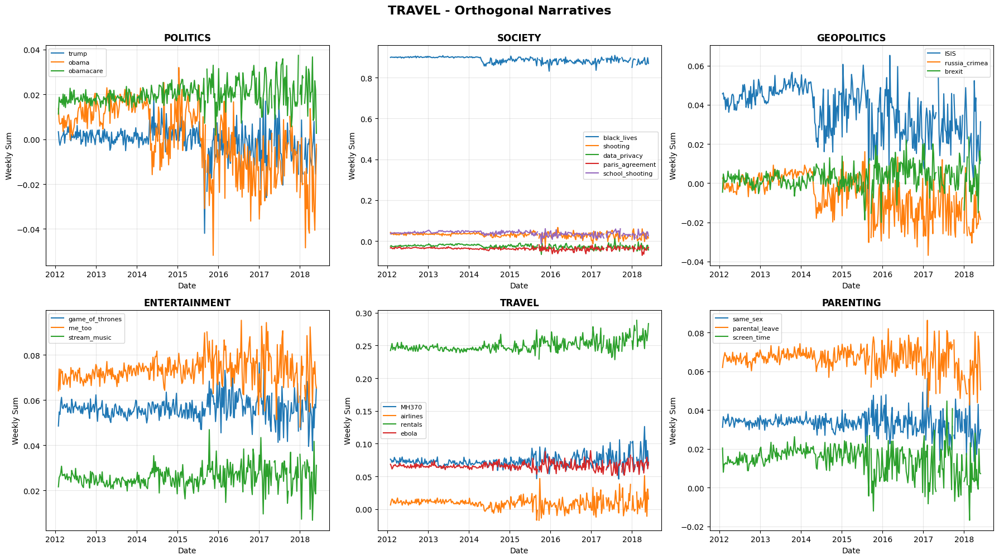

In [22]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())

""" Visualization of cosine time series for ORIGINAL narratives - GROUPED BY NEWS CATEGORY """

for news_cat in news_categories:
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create subplots: one per chapter (6 chapters)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for ax_idx, chapter in enumerate(chapter_names):
        chapter_narrative_cols = [col for col in narrative_cols if col.startswith(chapter + ':')]
        
        if not chapter_narrative_cols:
            axes[ax_idx].set_visible(False)
            continue
        
        for col in chapter_narrative_cols:
            cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
            dates = cosine_similarities.index
            narrative_name = col.split(':')[1]
            axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Original Narratives', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

""" Visualization of cosine time series for ORTHOGONAL narratives - GROUPED BY NEWS CATEGORY """

for news_cat in news_categories:
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create subplots: one per chapter (6 chapters)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for ax_idx, chapter in enumerate(chapter_names):
        chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
        if not chapter_orthogonal_cols:
            axes[ax_idx].set_visible(False)
            continue
        
        for col in chapter_orthogonal_cols:
            cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
            dates = cosine_similarities.index
            narrative_name = col.split(':')[1].replace('_orth', '')
            axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


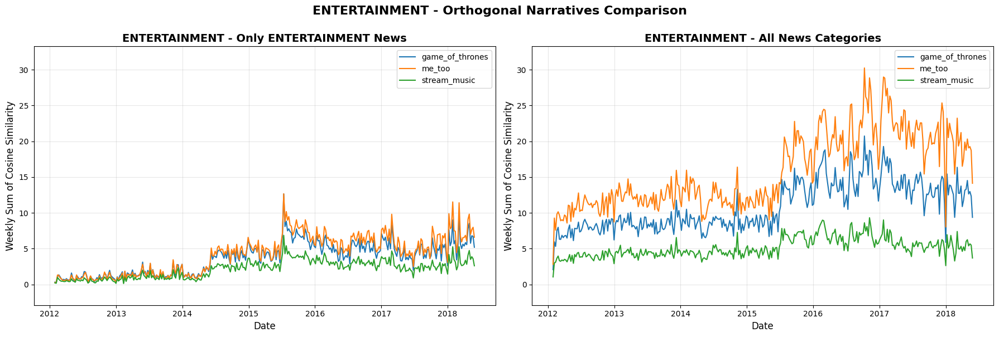

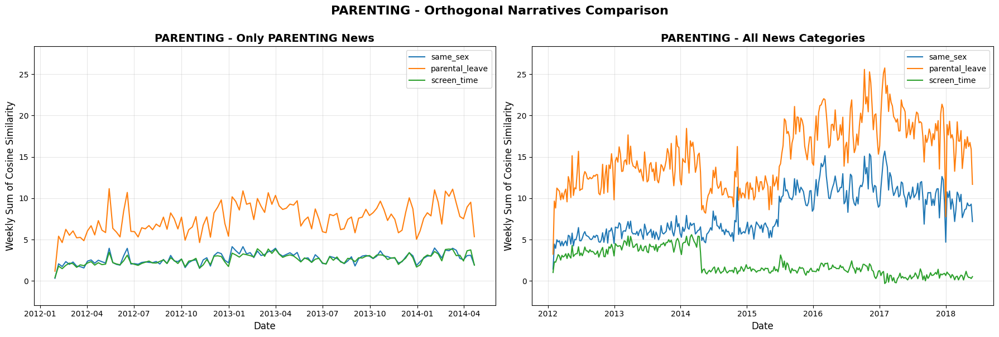

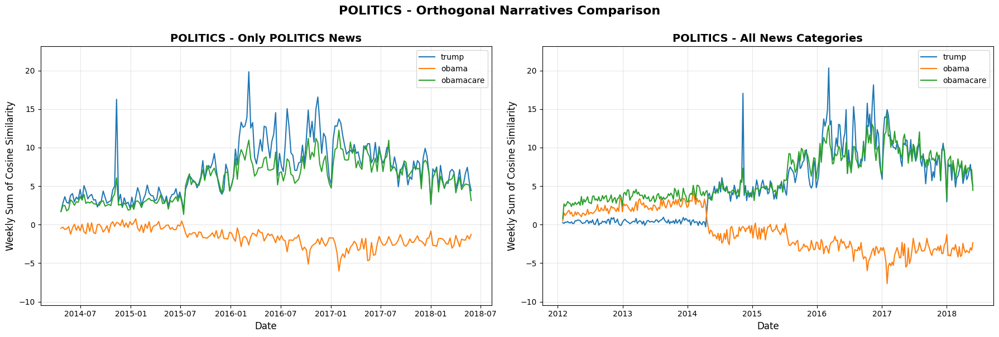

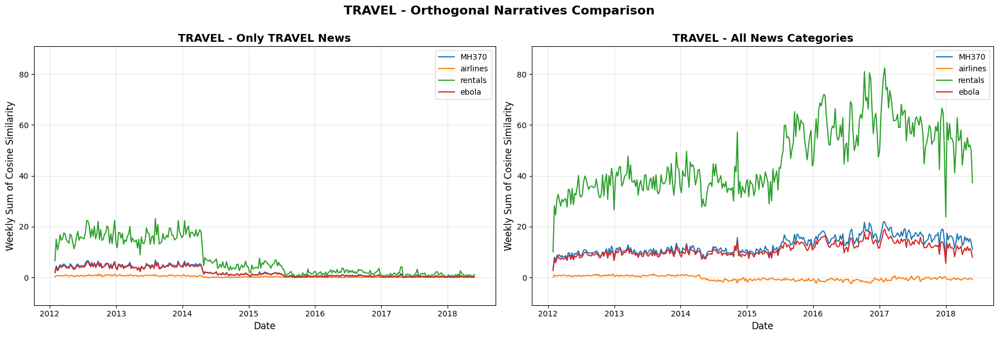

In [23]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - SIDE BY SIDE comparison """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create side-by-side figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    
    # Compute global min/max for this chapter's narratives
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # Only this category
        sim1 = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim1.min())
        y_max = max(y_max, sim1.max())
        
        # All categories
        sim2 = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim2.min())
        y_max = max(y_max, sim2.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # LEFT: Only this category
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name)
    
    ax1.set_title(f'{corresponding_chapter.upper()} - Only {news_cat} News', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=12)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=12)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # RIGHT: All categories
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name)
    
    ax2.set_title(f'{corresponding_chapter.upper()} - All News Categories', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=12)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=12)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives Comparison', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


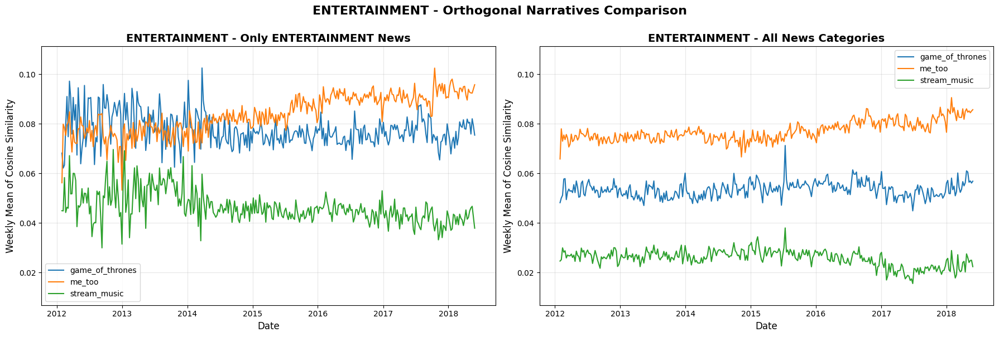

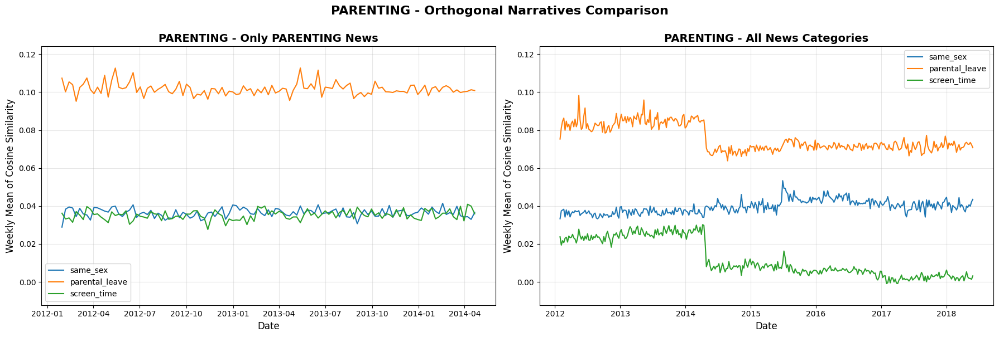

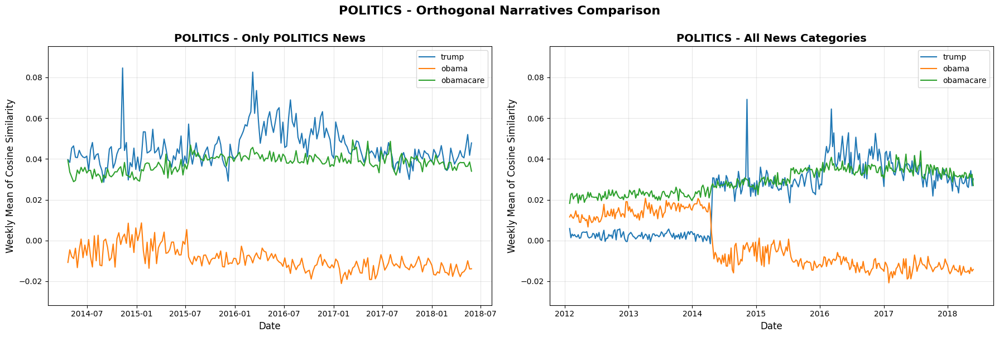

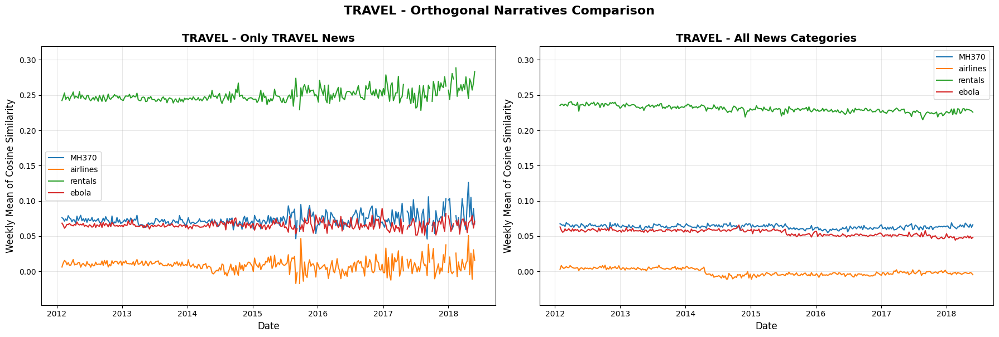

In [24]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - SIDE BY SIDE comparison """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data for this news category
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    
    # Create side-by-side figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    
    # Compute global min/max for this chapter's narratives
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # Only this category
        sim1 = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim1.min())
        y_max = max(y_max, sim1.max())
        
        # All categories
        sim2 = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim2.min())
        y_max = max(y_max, sim2.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # LEFT: Only this category
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name)
    
    ax1.set_title(f'{corresponding_chapter.upper()} - Only {news_cat} News', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=12)
    ax1.set_ylabel('Weekly Mean of Cosine Similarity', fontsize=12)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # RIGHT: All categories
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name)
    
    ax2.set_title(f'{corresponding_chapter.upper()} - All News Categories', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=12)
    ax2.set_ylabel('Weekly Mean of Cosine Similarity', fontsize=12)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives Comparison', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


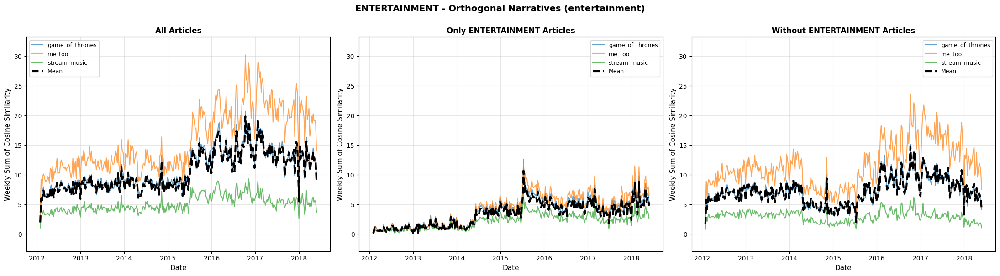

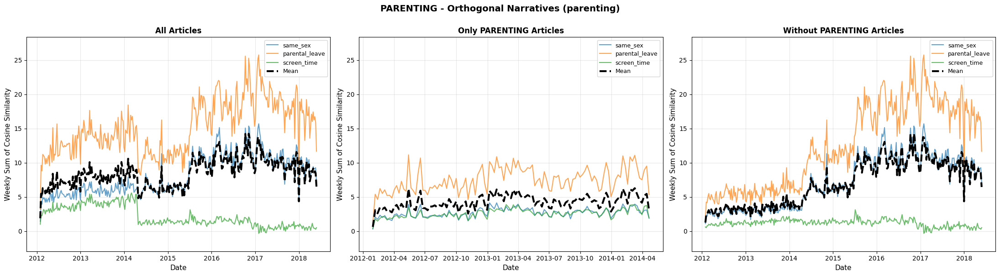

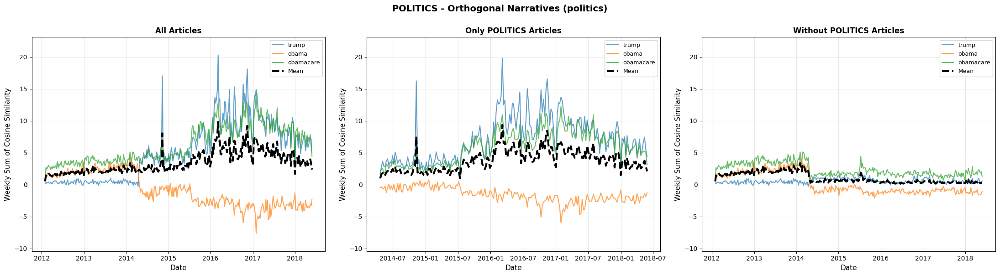

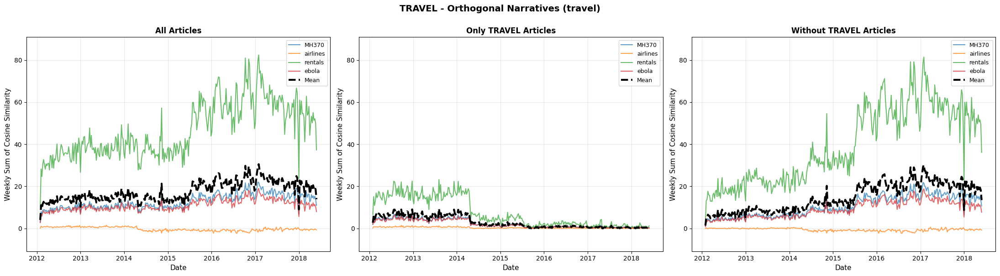

In [25]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - 3 GRAPHS PER CATEGORY """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    ts_df_without_cat = ts_df[ts_df['category'] != news_cat]
    
    # Create 3-column figure
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
    
    # Compute global min/max for consistent scaling
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # All data
        sim_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_all.min())
        y_max = max(y_max, sim_all.max())
        
        # Only this category
        sim_cat = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_cat.min())
        y_max = max(y_max, sim_cat.max())
        
        # Without this category
        sim_without = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        y_min = min(y_min, sim_without.min())
        y_max = max(y_max, sim_without.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # GRAPH 1: All data
    all_curves_1 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_1.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_1:
        mean_curve_1 = np.mean(all_curves_1, axis=0)
        ax1.plot(dates, mean_curve_1, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax1.set_title(f'All Articles', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=11)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # GRAPH 2: Only this category
    all_curves_2 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_2.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_2:
        mean_curve_2 = np.mean(all_curves_2, axis=0)
        ax2.plot(dates, mean_curve_2, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax2.set_title(f'Only {news_cat} Articles', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # GRAPH 3: Without this category
    all_curves_3 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax3.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_3.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_3:
        mean_curve_3 = np.mean(all_curves_3, axis=0)
        ax3.plot(dates, mean_curve_3, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax3.set_title(f'Without {news_cat} Articles', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=11)
    ax3.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax3.set_ylim(y_min, y_max)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives ({corresponding_chapter})', fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


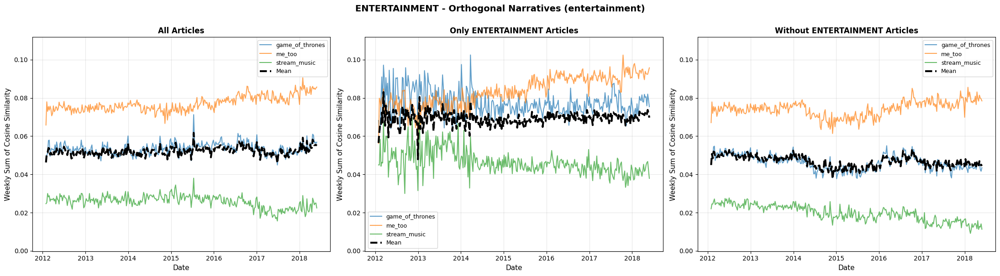

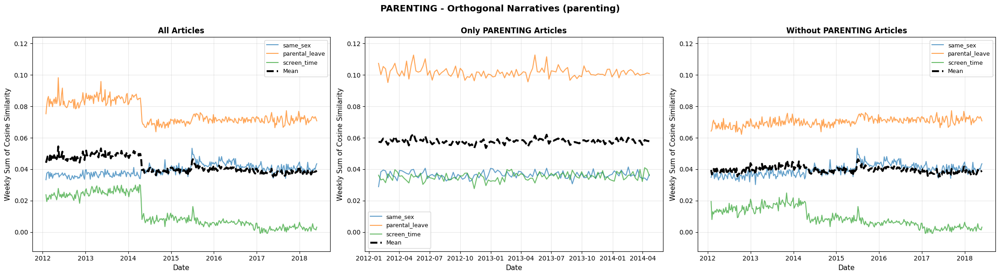

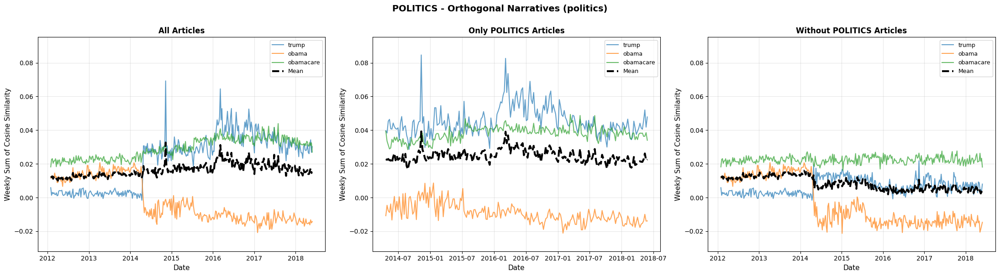

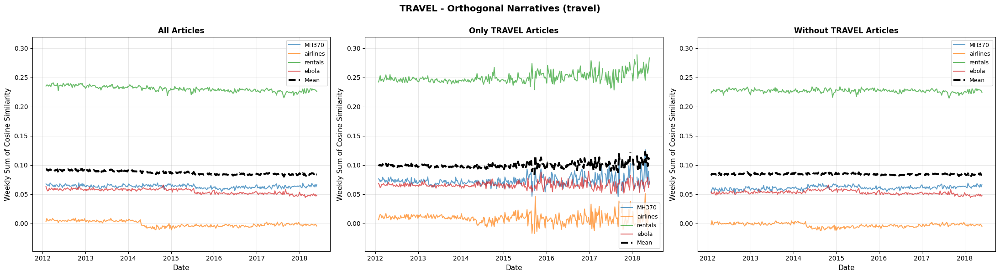

In [26]:
# Prepare data
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - 3 GRAPHS PER CATEGORY """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    ts_df_without_cat = ts_df[ts_df['category'] != news_cat]
    
    # Create 3-column figure
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
    
    # Compute global min/max for consistent scaling
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # All data
        sim_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_all.min())
        y_max = max(y_max, sim_all.max())
        
        # Only this category
        sim_cat = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_cat.min())
        y_max = max(y_max, sim_cat.max())
        
        # Without this category
        sim_without = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_without.min())
        y_max = max(y_max, sim_without.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # GRAPH 1: All data
    all_curves_1 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_1.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_1:
        mean_curve_1 = np.mean(all_curves_1, axis=0)
        ax1.plot(dates, mean_curve_1, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax1.set_title(f'All Articles', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=11)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # GRAPH 2: Only this category
    all_curves_2 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_2.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_2:
        mean_curve_2 = np.mean(all_curves_2, axis=0)
        ax2.plot(dates, mean_curve_2, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax2.set_title(f'Only {news_cat} Articles', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # GRAPH 3: Without this category
    all_curves_3 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax3.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_3.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_3:
        mean_curve_3 = np.mean(all_curves_3, axis=0)
        ax3.plot(dates, mean_curve_3, color='black', linewidth=3, label='Mean', linestyle='--')
    
    ax3.set_title(f'Without {news_cat} Articles', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=11)
    ax3.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax3.set_ylim(y_min, y_max)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives ({corresponding_chapter})', fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

## Essaie de nouvelles techniques d'orthogonalisation

**1. Ajustement itératif pour évitier les projections croisées**

In [27]:
import numpy as np

def orthogonalize_with_cross_penalty(N, max_iter=100, tol=1e-8, alpha=0.1):
    n, d = N.shape
    # Initialisation : Gram-Schmidt
    V = np.zeros((n, d))
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1

    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        # Ajustement pour projections croisées
        for i in range(n):
            for j in range(n):
                if j != i:
                    cross = np.dot(N[i], V[j]) - np.dot(N[i], V[i])
                    if cross > 0:
                        correction = alpha * (N[i] - np.dot(N[i], V[i])*V[i] - np.dot(N[i], V[j])*V[j])
                        V[i] += correction
                        V[i] /= np.linalg.norm(V[i])
        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break
    return V

In [28]:
matrix_orth_1 = orthogonalize_with_cross_penalty(narrative_matrix)
cosine_all_1 = cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, matrix_orth_1]))

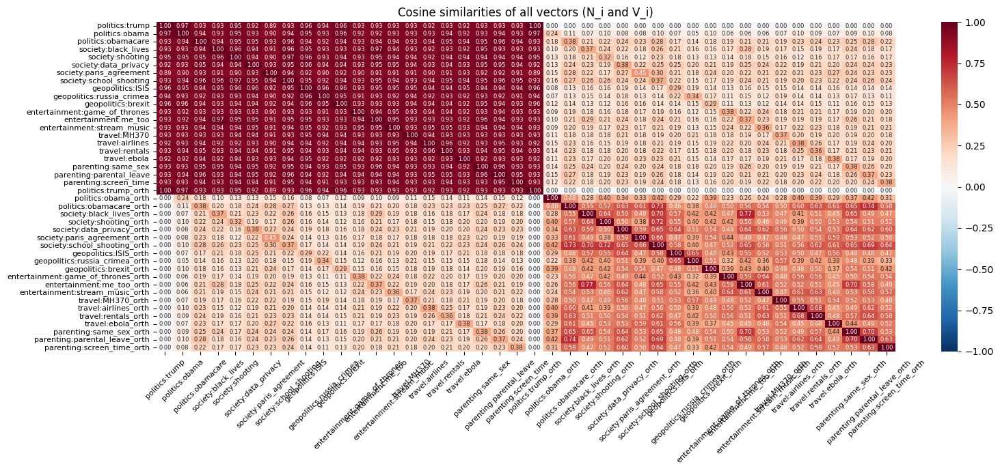

In [29]:
fig, axes = plt.subplots(1, 1, figsize=(16, 7))
# Heatmap for all vectors N_i and V_i
sns.heatmap(
    cosine_all_1,
    xticklabels=narrative_names + orthogonal_names,
    yticklabels=narrative_names + orthogonal_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

**2. Optimisation avec pénalités croisées**

In [30]:
import numpy as np

def orthogonal_global_penalty(N, n_restarts=10, max_iter=100, tol=1e-8):
    """
    Résout max min_i <N_i, V_i> s.t. V_i ⊥ V_j et ||V_i||=1
    Correction : chaque V_i reste aligné avec son propre N_i
    """
    n, d = N.shape
    best_V, best_score = None, -np.inf

    for restart in range(n_restarts):
        perm = np.random.permutation(n)
        V = np.zeros((n, d))

        # --- Initialisation : Gram-Schmidt ---
        for idx, i in enumerate(perm):
            v = N[i].copy()
            for j in perm[:idx]:
                v -= np.dot(v, V[j]) * V[j]
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        prev_score = -np.inf
        for _ in range(max_iter):
            # Mélanger l'ordre à chaque itération pour stabiliser
            perm_iter = np.random.permutation(n)
            for i in perm_iter:
                # Projection sur l'espace des autres vecteurs uniquement
                other_indices = [j for j in range(n) if j != i]
                if other_indices:
                    proj = V[other_indices].T @ (V[other_indices] @ N[i])
                else:
                    proj = 0
                v = N[i] - proj
                norm = np.linalg.norm(v)
                if norm > 1e-10:
                    V[i] = v / norm
                # S'assurer que le vecteur reste aligné avec N_i
                if np.dot(N[i], V[i]) < 0:
                    V[i] *= -1

            # Calcul du score minimal
            score = min(np.dot(N[i], V[i]) for i in range(n))
            if score - prev_score < tol:
                break
            prev_score = score

        # Garder la meilleure solution parmi les redémarrages
        if score > best_score:
            best_V, best_score = V.copy(), score

    return best_V

In [31]:
matrix_orth_2 = orthogonal_global_penalty(narrative_matrix)
cosine_all_2 = cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, matrix_orth_2]))

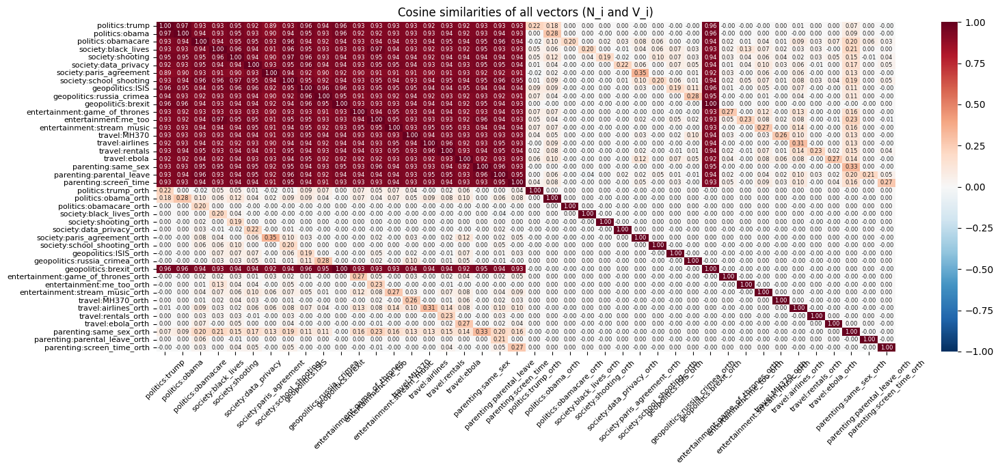

In [32]:
fig, axes = plt.subplots(1, 1, figsize=(16, 7))
# Heatmap for all vectors N_i and V_i
sns.heatmap(
    cosine_all_2,
    xticklabels=narrative_names + orthogonal_names,
    yticklabels=narrative_names + orthogonal_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

In [33]:
import numpy as np

def solve_orthogonal_narratives_with_fixed_extra(N, max_iter=100, tol=1e-8):
    """
    Algorithme avec vecteur supplémentaire V_extra fixé tel que V_extra = N_extra.
    Chaque V_i reste aligné avec son N_i, orthogonal à tous les autres V_j.
    """
    n, d = N.shape

    # Ajouter N_extra comme dernier vecteur
    N_extra = np.random.randn(1, d)
    N_ext = np.vstack([N, N_extra])
    n_ext = n + 1

    V = np.zeros((n_ext, d))

    # Initialisation : Gram-Schmidt
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1

    # V_extra = N_extra (fixé)
    V[-1] = N_extra / np.linalg.norm(N_extra)

    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            V[i] = v / np.linalg.norm(v)
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    return V[:n], score, V[-1]  # Retourne les vrais V_i et le V_extra

In [34]:
matrix_orth_2, _, _ = solve_orthogonal_narratives_with_fixed_extra(narrative_matrix)
cosine_all_2 = cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, matrix_orth_2]))

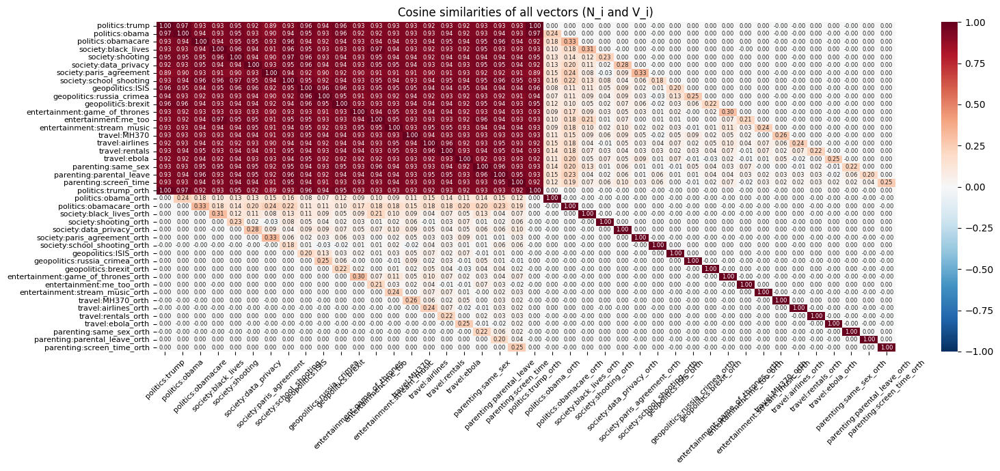

In [35]:
fig, axes = plt.subplots(1, 1, figsize=(16, 7))
# Heatmap for all vectors N_i and V_i
sns.heatmap(
    cosine_all_2,
    xticklabels=narrative_names + orthogonal_names,
    yticklabels=narrative_names + orthogonal_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

In [36]:
import numpy as np

def solve_orthogonal_narratives_with_extras(N, n_extra=4, max_iter=100, tol=1e-8):
    """
    Résout max min_i <N_i, V_i> s.t. V_i ⊥ V_j et ||V_i||=1
    Avec n_extra vecteurs supplémentaires fixes : V_extra = N_extra
    Chaque vrai V_i reste aligné avec son N_i
    """
    n, d = N.shape

    # Générer n_extra vecteurs tampons aléatoires
    N_extra = np.random.randn(n_extra, d)
    N_ext = np.vstack([N, N_extra])
    n_ext = n + n_extra

    # Initialisation des V_i
    V = np.zeros((n_ext, d))

    # --- Initialisation Gram-Schmidt pour les vrais N_i ---
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1

    # Fixer les vecteurs tampons : V_extra = N_extra normalisés
    for k in range(n_extra):
        v = N_extra[k] / np.linalg.norm(N_extra[k])
        V[n + k] = v

    # --- Boucle d'optimisation ---
    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            # Orthogonaliser par rapport aux autres vecteurs (y compris les extras)
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            # Forcer la direction vers N_i
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        # Score minimal sur les vrais N_i
        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    # Retourner les vrais V_i et éventuellement les V_extra
    return V[:n], score, V[n:]

In [37]:
matrix_orth_2, _, _ = solve_orthogonal_narratives_with_fixed_extra(narrative_matrix)
cosine_all_2 = cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, matrix_orth_2]))

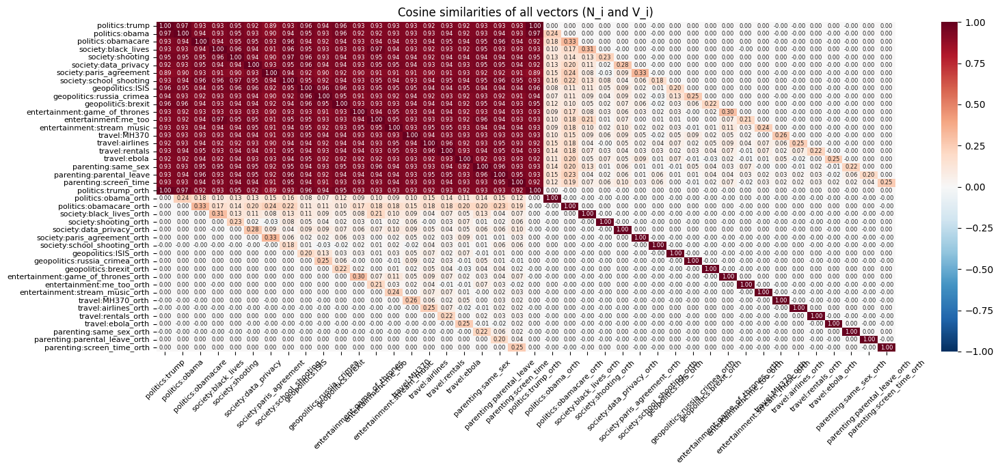

In [38]:
fig, axes = plt.subplots(1, 1, figsize=(16, 7))
# Heatmap for all vectors N_i and V_i
sns.heatmap(
    cosine_all_2,
    xticklabels=narrative_names + orthogonal_names,
    yticklabels=narrative_names + orthogonal_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

In [39]:
import numpy as np
import matplotlib.pyplot as plt

def solve_orthogonal_narratives_with_extras_and_cosine(N, n_extra=1, max_iter=100, tol=1e-8):
    """
    Résout max min_i <N_i, V_i> s.t. V_i ⊥ V_j et ||V_i||=1
    Avec n_extra vecteurs supplémentaires fixes : V_extra = N_extra
    Visualisation de la matrice des cosinus entre N_ext et V
    """
    n, d = N.shape

    # Générer n_extra vecteurs tampons aléatoires
    N_extra = np.random.randn(n_extra, d)
    N_ext = np.vstack([N, N_extra])
    n_ext = n + n_extra

    # Initialisation des V_i
    V = np.zeros((n_ext, d))

    # --- Initialisation Gram-Schmidt pour les vrais N_i ---
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1

    # Fixer les vecteurs tampons : V_extra = N_extra normalisés
    for k in range(n_extra):
        v = N_extra[k] / np.linalg.norm(N_extra[k])
        V[n + k] = v

    # --- Boucle d'optimisation ---
    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    # --- Calcul de la matrice des cosinus ---
    # Normalisation pour cosinus
    cosine_matrix = cosine_similarity(np.vstack([N_ext, V]))

    # --- Visualisation ---
    fig, axes = plt.subplots(1, 1, figsize=(16, 7))
    # Heatmap for all vectors N_i and V_i
    sns.heatmap(
        cosine_matrix,
        xticklabels=[f'N_{i}' for i in range(n_ext)] + [f'V_{i}' for i in range(n_ext)],
        yticklabels=[f'N_{i}' for i in range(n_ext)] + [ f'V_{i}' for i in range(n_ext)],
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        annot_kws={'size': 6}
    )
    axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
    axes.tick_params(axis='x', rotation=45, labelsize=8)
    axes.tick_params(axis='y', rotation=0, labelsize=8)

    plt.tight_layout()
    plt.show()

    return V[:n], score, V[n:], cosine_matrix

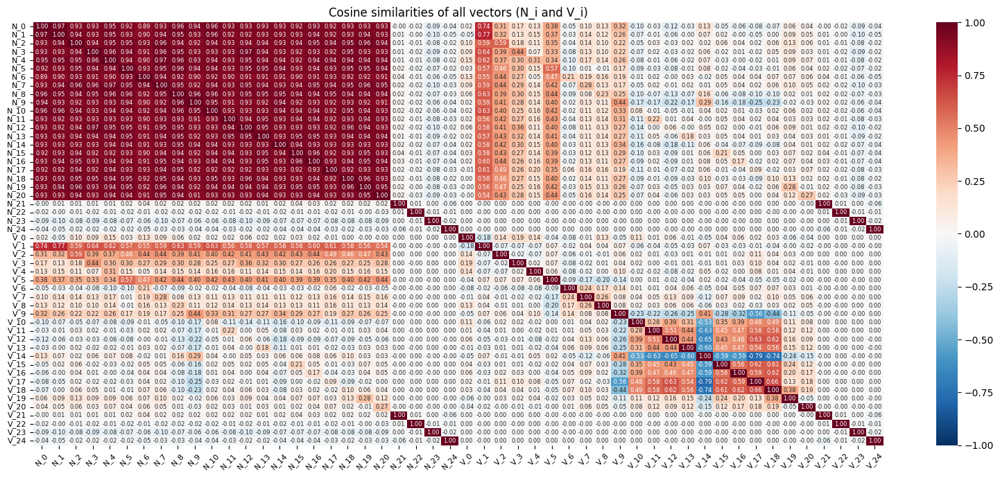

(array([[ 0.03443524,  0.03060113, -0.03498958, ..., -0.02413989,
          0.0595234 ,  0.01940555],
        [-0.03380531,  0.02304887,  0.02248347, ..., -0.01743067,
         -0.00467311, -0.04629178],
        [-0.00158811,  0.04711577, -0.03713353, ..., -0.03059466,
          0.00660219,  0.0602565 ],
        ...,
        [ 0.05142024, -0.01641335,  0.02664812, ...,  0.03509832,
         -0.00554353, -0.04757386],
        [ 0.0688385 , -0.10046398,  0.00631432, ...,  0.0271354 ,
          0.01255935, -0.02556143],
        [ 0.05456672, -0.02258184, -0.03783912, ...,  0.06438416,
          0.00247499, -0.00265248]]),
 np.float64(0.7067697673591824),
 array([[-0.0147537 , -0.00598093,  0.01960675, ..., -0.00952586,
         -0.07734108,  0.01922867],
        [ 0.02070272,  0.06400304, -0.06377942, ..., -0.00421403,
          0.04810526, -0.02054335],
        [-0.02155921,  0.10516074,  0.01819539, ...,  0.05898852,
         -0.04832698, -0.0069037 ],
        [ 0.00366476, -0.04667567,

In [40]:
solve_orthogonal_narratives_with_extras_and_cosine(narrative_matrix, n_extra=4)

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

def reorthogonalize(V):
    """Gram-Schmidt complet pour orthogonaliser tous les vecteurs"""
    n_ext, d = V.shape
    for i in range(n_ext):
        for j in range(i):
            V[i] -= np.dot(V[i], V[j]) * V[j]
        norm = np.linalg.norm(V[i])
        if norm > 1e-10:
            V[i] /= norm
    return V

def solve_orthogonal_narratives_with_extras_visualization(N, n_extra=1, max_iter=100, tol=1e-8, scale_extra=0.01):
    """
    Optimisation de V_i orthogonaux alignés avec N_i
    Avec n_extra vecteurs tampons fixes : V_extra = N_extra
    Visualisation de toutes les similitudes cosinus (N_i et V_i)
    """
    n, d = N.shape

    # --- Générer vecteurs tampons ---
    k_ext = np.random.randint(0, n, n_extra)
    N_extra = []
    for k in k_ext:
        N_extra.append(N[k] + np.random.normal(scale=scale_extra, size=d))  # Perturbation légère
    N_extra = np.array(N_extra)
    N_ext = np.vstack([N, N_extra])
    n_ext = n + n_extra

    # --- Initialisation des V_i ---
    V = np.zeros((n_ext, d))
    # Initialisation Gram-Schmidt pour vrais N_i
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1
    # Fixer V_extra = N_extra normalisés
    for k in range(n_extra):
        v = N_extra[k] / np.linalg.norm(N_extra[k])
        V[n + k] = v

    # --- Boucle d'optimisation ---
    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        # --- Ré-orthogonalisation complète pour garantir V_i ⊥ V_j ---
        V = reorthogonalize(V)

        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    # --- Calcul de la matrice des cosinus N_ext + V ---
    all_vectors = np.vstack([N_ext, V])
    cosine_matrix = cosine_similarity(all_vectors)

    # --- Visualisation avec Seaborn ---
    fig, axes = plt.subplots(1, 1, figsize=(16, 7))
    labels = [f'N_{i}' for i in range(n_ext)] + [f'V_{i}' for i in range(n_ext)]
    sns.heatmap(
        cosine_matrix,
        xticklabels=labels,
        yticklabels=labels,
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        annot_kws={'size': 6}
    )
    axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
    axes.tick_params(axis='x', rotation=45, labelsize=8)
    axes.tick_params(axis='y', rotation=0, labelsize=8)
    plt.tight_layout()
    plt.show()

    return V[:n], score, V[n:], cosine_matrix

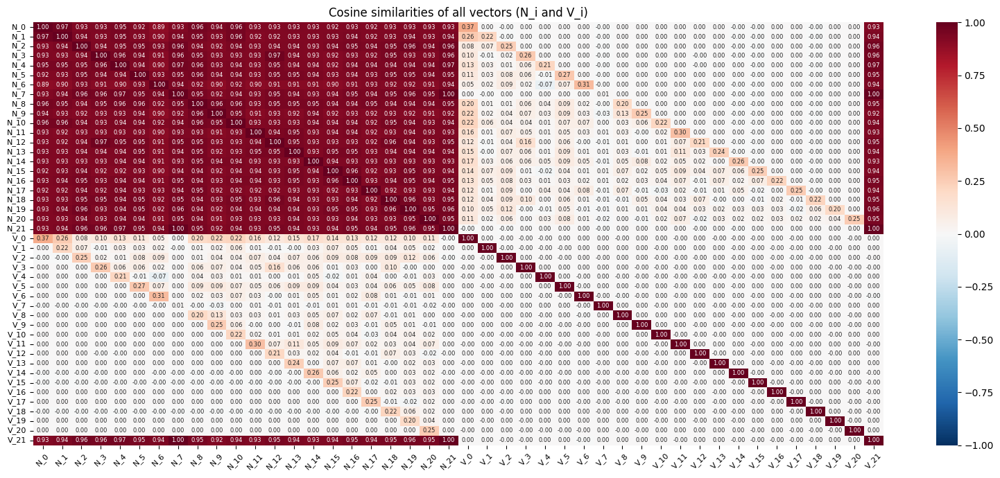

(array([[-0.05572793, -0.02048721,  0.01022821, ..., -0.02617198,
         -0.05715245, -0.007563  ],
        [-0.01830091,  0.01344556,  0.0103824 , ...,  0.00883543,
         -0.02565126, -0.02777975],
        [-0.0137373 ,  0.05489008, -0.04113124, ..., -0.02095902,
         -0.01896795,  0.04584249],
        ...,
        [-0.00332031, -0.03270146,  0.05174517, ..., -0.00881088,
         -0.09093585,  0.03781808],
        [ 0.04068192, -0.0974114 , -0.00316378, ...,  0.0135269 ,
          0.00718078, -0.02824786],
        [ 0.06287794, -0.05990744, -0.04821241, ...,  0.06047409,
         -0.01299701,  0.00758179]]),
 np.float64(0.27800579695829775),
 array([[ 1.38484319e-02, -2.02510755e-02, -1.46392257e-02,
          3.86149419e-03,  4.74733843e-03,  1.66961439e-02,
         -2.25974134e-03, -1.28818293e-02, -4.38160090e-03,
         -1.66318801e-02, -2.30206256e-02,  1.44380259e-02,
         -1.25520056e-02,  7.64236173e-03, -1.01480450e-02,
         -8.84195149e-03, -5.64285412e-

In [42]:
solve_orthogonal_narratives_with_extras_visualization(narrative_matrix, n_extra=1)

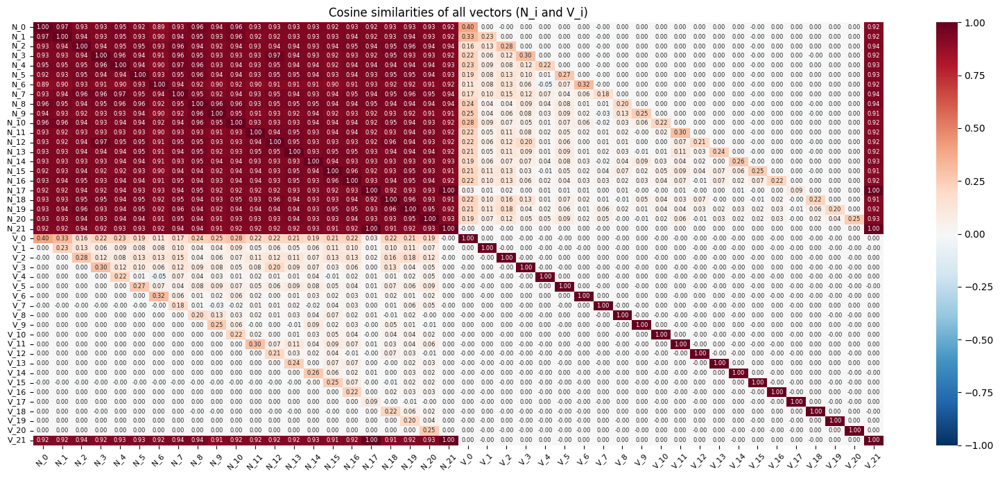

(array([[ 0.03137346, -0.03532987, -0.00618072, ...,  0.00568681,
         -0.00829984, -0.03066638],
        [ 0.01832383,  0.01021059,  0.00249258, ...,  0.02073662,
          0.00028634, -0.03188975],
        [ 0.06094128,  0.03739364, -0.05163014, ...,  0.00544815,
          0.0302873 ,  0.02966866],
        ...,
        [-0.00159644, -0.03296893,  0.05149468, ..., -0.0093652 ,
         -0.09158995,  0.03742991],
        [ 0.04348949, -0.09771964, -0.00369794, ...,  0.01085097,
          0.00868799, -0.02740198],
        [ 0.06429153, -0.05969702, -0.04848357, ...,  0.05761951,
         -0.01046132,  0.00905838]]),
 np.float64(2.4109953062088105),
 array([[-2.18957767e-02, -1.34691044e-02, -8.04958278e-03,
          2.00959616e-02, -3.81559045e-03,  1.36796982e-02,
         -1.68018316e-02,  1.29209176e-02,  1.67129934e-03,
         -1.81418005e-02, -1.78284874e-03,  8.15901130e-03,
         -2.54890690e-02,  6.25659266e-03,  1.40200199e-03,
         -1.76920537e-02, -1.70508707e-0

In [43]:
solve_orthogonal_narratives_with_extras_visualization(narrative_matrix, n_extra=1, scale_extra=0.1)

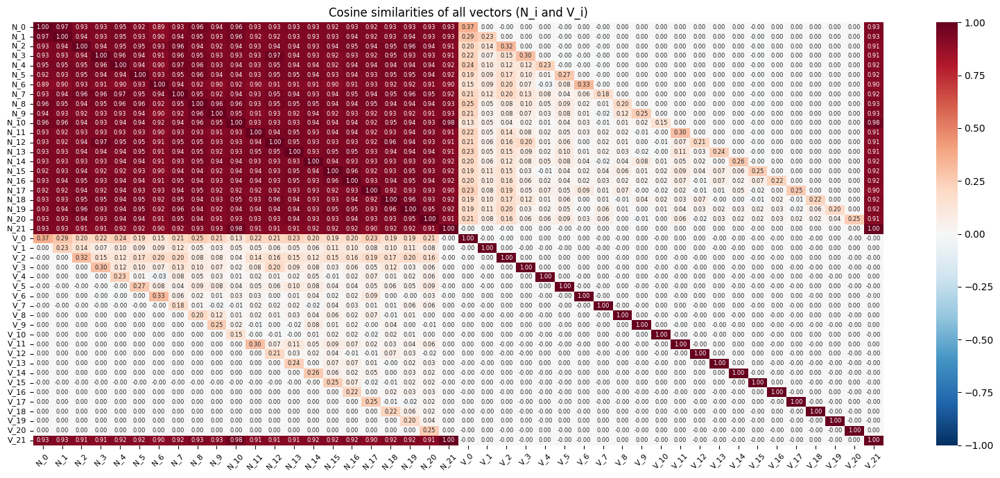

(array([[ 0.03020821, -0.03921307,  0.01541718, ..., -0.00672319,
         -0.0033737 , -0.00602013],
        [ 0.01914468,  0.0079292 ,  0.00964572, ...,  0.01701253,
          0.00169714, -0.0248609 ],
        [ 0.04225996,  0.03772349, -0.03779013, ..., -0.00601549,
          0.03011909,  0.04469591],
        ...,
        [-0.00257591, -0.03278156,  0.05158323, ..., -0.00937903,
         -0.09068004,  0.0380719 ],
        [ 0.04742495, -0.09986358, -0.00362704, ...,  0.00904817,
          0.00748932, -0.03011683],
        [ 0.06653651, -0.06033202, -0.04861084, ...,  0.05743218,
         -0.01228616,  0.00756245]]),
 np.float64(4.421817522489872),
 array([[-2.01271458e-02, -1.29048782e-02, -1.66470440e-02,
          1.35033088e-02, -7.05534958e-03, -9.46925340e-03,
          4.93103930e-03, -2.53350395e-02,  4.96567621e-03,
          5.82442539e-03, -1.45820605e-02, -2.81684899e-03,
          9.76277012e-03,  8.00814941e-03,  1.47178233e-02,
         -1.89663949e-02,  2.19802595e-03

In [44]:
solve_orthogonal_narratives_with_extras_visualization(narrative_matrix, n_extra=1, scale_extra=0.25)

In [45]:
#On force le V_extra à ressembler à V_1
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

def reorthogonalize(V):
    """Gram-Schmidt complet pour orthogonaliser tous les vecteurs"""
    n_ext, d = V.shape
    for i in range(n_ext):
        for j in range(i):
            V[i] -= np.dot(V[i], V[j]) * V[j]
        norm = np.linalg.norm(V[i])
        if norm > 1e-10:
            V[i] /= norm
    return V

def solve_orthogonal_narratives_with_extras_visualization(N, n_extra=1, max_iter=100, tol=1e-8, scale_extra=0.01):
    """
    Optimisation de V_i orthogonaux alignés avec N_i
    Avec n_extra vecteurs tampons fixes : V_extra = N_extra
    Visualisation de toutes les similitudes cosinus (N_i et V_i)
    """
    n, d = N.shape

    # --- Générer vecteurs tampons ---
    k_ext = [0]
    N_extra = []
    for k in k_ext:
        N_extra.append(N[k] + np.random.normal(scale=scale_extra, size=d))  # Perturbation légère
    N_extra = np.array(N_extra)
    N_ext = np.vstack([N, N_extra])
    n_ext = n + n_extra

    # --- Initialisation des V_i ---
    V = np.zeros((n_ext, d))
    # Initialisation Gram-Schmidt pour vrais N_i
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1
    # Fixer V_extra = N_extra normalisés
    for k in range(n_extra):
        v = N_extra[k] / np.linalg.norm(N_extra[k])
        V[n + k] = v

    # --- Boucle d'optimisation ---
    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        # --- Ré-orthogonalisation complète pour garantir V_i ⊥ V_j ---
        V = reorthogonalize(V)

        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    # --- Calcul de la matrice des cosinus N_ext + V ---
    all_vectors = np.vstack([N_ext, V])
    cosine_matrix = cosine_similarity(all_vectors)

    # --- Visualisation avec Seaborn ---
    fig, axes = plt.subplots(1, 1, figsize=(16, 7))
    labels = [f'N_{i}' for i in range(n_ext)] + [f'V_{i}' for i in range(n_ext)]
    sns.heatmap(
        cosine_matrix,
        xticklabels=labels,
        yticklabels=labels,
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        annot_kws={'size': 6}
    )
    axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
    axes.tick_params(axis='x', rotation=45, labelsize=8)
    axes.tick_params(axis='y', rotation=0, labelsize=8)
    plt.tight_layout()
    plt.show()

    return V[:n], score, V[n:], cosine_matrix

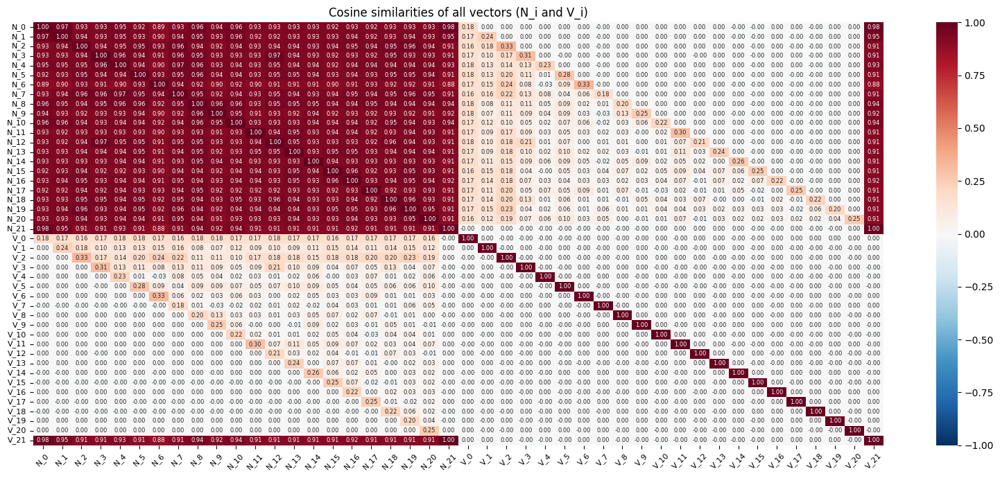

(array([[ 0.05019832,  0.0274052 ,  0.00854751, ..., -0.01421729,
          0.01193706, -0.03135954],
        [ 0.00865058,  0.01774376,  0.00327456, ...,  0.01455255,
          0.00250177, -0.02259587],
        [ 0.02995292,  0.04451014, -0.0424619 , ..., -0.00868206,
          0.02946807,  0.04615414],
        ...,
        [-0.0019611 , -0.03259739,  0.051646  , ..., -0.00954129,
         -0.09062851,  0.03768015],
        [ 0.04247473, -0.09891871, -0.00397149, ...,  0.01111766,
          0.00772337, -0.02680566],
        [ 0.06834837, -0.05792045, -0.04833602, ...,  0.05760233,
         -0.01165368,  0.00657555]]),
 np.float64(5.156859340765269),
 array([[-1.72436045e-02, -3.19972278e-02, -1.16225000e-02,
         -1.11829655e-03, -8.93655086e-03,  1.44538958e-02,
          1.32360842e-02, -1.03941032e-03,  1.54348575e-02,
         -2.10990721e-03, -4.80662437e-03,  1.54748593e-02,
         -3.39864376e-03,  3.44174874e-03,  1.96415892e-02,
          2.10939186e-03, -1.55626097e-02

In [46]:
solve_orthogonal_narratives_with_extras_visualization(narrative_matrix, n_extra=1, scale_extra=0.2)

In [47]:
#On force le V_extra à ressembler à V_1
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

def reorthogonalize(V):
    """Gram-Schmidt complet pour orthogonaliser tous les vecteurs"""
    n_ext, d = V.shape
    for i in range(n_ext):
        for j in range(i):
            V[i] -= np.dot(V[i], V[j]) * V[j]
        norm = np.linalg.norm(V[i])
        if norm > 1e-10:
            V[i] /= norm
    return V

def solve_orthogonal_narratives_with_mean_as_extra_visualization(N, n_extra=1, max_iter=100, tol=1e-8, scale_extra=0.01):
    """
    Optimisation de V_i orthogonaux alignés avec N_i
    Avec n_extra vecteurs tampons fixes : V_extra = N_extra
    Visualisation de toutes les similitudes cosinus (N_i et V_i)
    """
    n, d = N.shape
    for i in range(n):
        N[i] /= np.linalg.norm(N[i]) 
        
    # --- Générer vecteurs tampons ---
      # Perturbation légère
    N_extra = np.array([np.mean(N,axis=0)])
    N_ext = np.vstack([N, N_extra])
    n_ext = n + n_extra

    # --- Initialisation des V_i ---
    V = np.zeros((n_ext, d))
    # Initialisation Gram-Schmidt pour vrais N_i
    for i in range(n):
        v = N[i].copy()
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        V[i] = v / np.linalg.norm(v)
        if np.dot(N[i], V[i]) < 0:
            V[i] *= -1
    # Fixer V_extra = N_extra normalisés
    for k in range(n_extra):
        v = N_extra[k] / np.linalg.norm(N_extra[k])
        V[n + k] = v

    # --- Boucle d'optimisation ---
    for _ in range(max_iter):
        prev_score = min(np.dot(N[i], V[i]) for i in range(n))
        for i in range(n):
            other_indices = [j for j in range(n_ext) if j != i]
            proj = V[other_indices].T @ (V[other_indices] @ N[i])
            v = N[i] - proj
            norm = np.linalg.norm(v)
            if norm > 1e-10:
                V[i] = v / norm
            if np.dot(N[i], V[i]) < 0:
                V[i] *= -1

        # --- Ré-orthogonalisation complète pour garantir V_i ⊥ V_j ---
        #V = reorthogonalize(V)

        score = min(np.dot(N[i], V[i]) for i in range(n))
        if abs(score - prev_score) < tol:
            break

    # --- Calcul de la matrice des cosinus N_ext + V ---
    all_vectors = np.vstack([N_ext, V])
    cosine_matrix = cosine_similarity(all_vectors)

    # --- Visualisation avec Seaborn ---
    fig, axes = plt.subplots(1, 1, figsize=(16, 7))
    labels = [f'N_{i}' for i in range(n_ext)] + [f'V_{i}' for i in range(n_ext)]
    sns.heatmap(
        cosine_matrix,
        xticklabels=labels,
        yticklabels=labels,
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        annot_kws={'size': 6}
    )
    axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
    axes.tick_params(axis='x', rotation=45, labelsize=8)
    axes.tick_params(axis='y', rotation=0, labelsize=8)
    plt.tight_layout()
    plt.show()

    return V[:n], score, V[n:], cosine_matrix

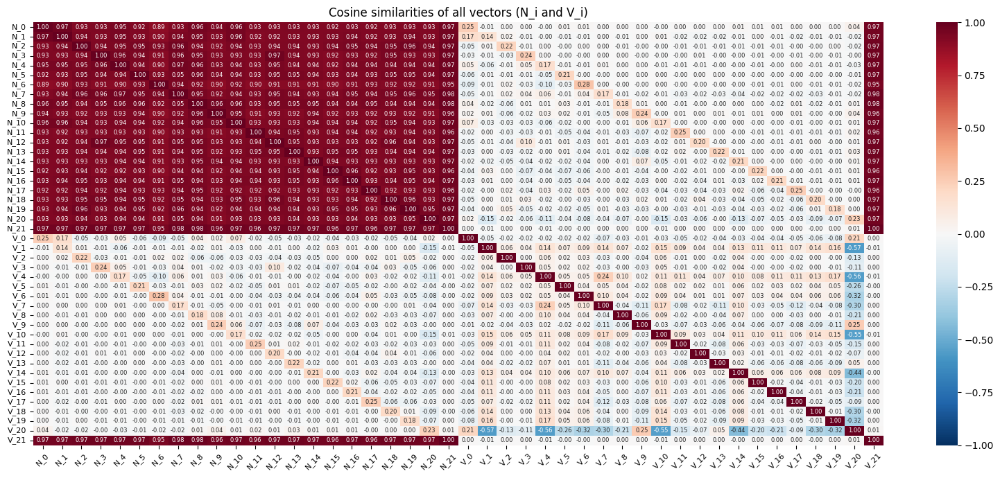

(array([[ 0.00822912, -0.03960625,  0.02020222, ...,  0.01028841,
         -0.01833447, -0.02033176],
        [-0.03765537,  0.04991384,  0.03479869, ..., -0.01337997,
         -0.01709819, -0.03250673],
        [ 0.03359032,  0.0610716 , -0.02640645, ..., -0.00320673,
          0.0187366 ,  0.03366908],
        ...,
        [-0.05037181,  0.00616587,  0.06715711, ..., -0.03194725,
         -0.08073679,  0.03061401],
        [ 0.01061829, -0.06978183,  0.01568596, ..., -0.01317696,
          0.01399164, -0.02495096],
        [ 0.0567228 , -0.05400695, -0.05062488, ...,  0.0496671 ,
         -0.02939186,  0.01073054]]),
 np.float64(0.14230409179538067),
 array([[-5.50971786e-03, -2.05881018e-02, -1.62649620e-02,
          1.10978857e-02,  1.89200172e-03,  8.81231856e-03,
         -8.95274337e-04, -1.14904409e-02,  1.91281259e-03,
         -3.85608961e-04, -9.94851720e-03,  1.55240577e-02,
         -1.70222651e-02, -2.99846660e-03,  5.77293662e-03,
         -7.30495807e-03, -8.31024535e-

In [48]:
solve_orthogonal_narratives_with_mean_as_extra_visualization(narrative_matrix, n_extra=1, scale_extra=0.2)

# Tests pour changer les narratifs #

Le but est de trouver des narratifs qui soient plus en lien avec les articles de la base de données

In [57]:
sampled_df = ts_df.sample(frac=0.01, random_state=42)
headline_str = " ".join(sampled_df['headline'].astype(str))

print(headline_str)

'Biggest Loser' Host Bob Harper Unconscious For Two Days After Heart Attack The Big Battle In 'Game Of Thrones' Season 6 Will Be Insane Just A Reminder That Hugh Grant's Middle Name Is 'Mungo' 'Noah' Floats With $15.2 Million On Opening Day 8 Cool, Creative Subscription Services Just For Kids! Ex-Top CIA Official: Brennan Is Doing Putin's 'Bidding' By Speculating About Trump Blackmail Donald Trump Got Clap-Happy During The State Of The Union, And Twitter Noticed A Dying Parent's List Obama's SXSW Appearance Coincides With Open Carry Protest Donald Trump Picks Dow Chemical's Andrew Liveris To Head American Manufacturing Council Selective Mutism: How A 6-Year-Old Was Finally 'Cured' Of Her Anxiety Disorder Too Dumb To Collude?  Is Trump Jr.'s Conduct Criminal or Just Criminally Clueless? 19 Signs You Have An Incurable Case Of Wanderlust The Joule Hotel -- A Dallas Destination That Will Ignite Your Creative Spirit Gun Advocate Says Only Voter ID Can Prevent Right-Wing Armed Insurgencies F

In [58]:
sampled_df = ts_df.sample(frac=0.01, random_state=42)
headline_str = " ".join(sampled_df['headline'].astype(str))

print(headline_str)

'Biggest Loser' Host Bob Harper Unconscious For Two Days After Heart Attack The Big Battle In 'Game Of Thrones' Season 6 Will Be Insane Just A Reminder That Hugh Grant's Middle Name Is 'Mungo' 'Noah' Floats With $15.2 Million On Opening Day 8 Cool, Creative Subscription Services Just For Kids! Ex-Top CIA Official: Brennan Is Doing Putin's 'Bidding' By Speculating About Trump Blackmail Donald Trump Got Clap-Happy During The State Of The Union, And Twitter Noticed A Dying Parent's List Obama's SXSW Appearance Coincides With Open Carry Protest Donald Trump Picks Dow Chemical's Andrew Liveris To Head American Manufacturing Council Selective Mutism: How A 6-Year-Old Was Finally 'Cured' Of Her Anxiety Disorder Too Dumb To Collude?  Is Trump Jr.'s Conduct Criminal or Just Criminally Clueless? 19 Signs You Have An Incurable Case Of Wanderlust The Joule Hotel -- A Dallas Destination That Will Ignite Your Creative Spirit Gun Advocate Says Only Voter ID Can Prevent Right-Wing Armed Insurgencies F

In [59]:
sampled_df = ts_df.sample(frac=0.01, random_state=31)
headline_str = " ".join(sampled_df['headline'].astype(str))

print(headline_str)

Watch Highlights From The Last GOP Debate Before The New Hampshire Primary Jorge Ramos: Trump Is 'Loudest Voice Of Intolerance, Hatred and Division' In U.S. What Getting a Job Feels Like Once You're a Mother The Super-Bowl-Watching Nuns Are Still The Best Part Of This Game Food Stamps Are Holding Up The Republican Agenda George Lucas Clears Up That Controversial Han Solo Gunfight Cynthia Nixon Challenges Andrew Cuomo To 1-On-1 Televised Debate Here's What Ned Stark Whispered During His 'Game Of Thrones' Death Teaching Kids Patience: Pamela Druckerman And Our Readers Share Their Best Advice Lady Gaga And Taylor Kinney Channel Classic Hollywood Glamour On Golden Globes Red Carpet Vietnam, Then and Now Kirby Dick and Amy Ziering Target The Hunting Ground 11 Reasons Why You Should Visit Mexico City Immediately Woman Captures What We All Would Look Like If We Saw Beyoncé In Person Popcorn Preview: House of Cards (2013) Is There Such a Thing As Too Young to Travel? Here's Why You Should Pay 

In [ ]:
sampled_df = ts_df.sample(frac=0.01, random_state=2024)
headline_str = " ".join(sampled_df['headline'].astype(str))

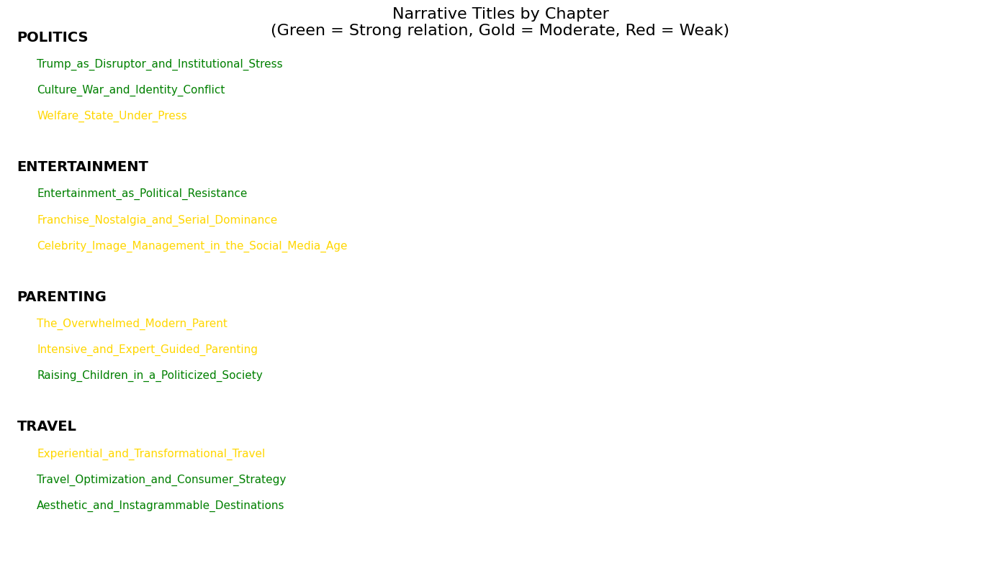

In [60]:
import matplotlib.pyplot as plt

# --- Your narrative structure ---
dict_narratives = {
    "politics": [
        "Trump_as_Disruptor_and_Institutional_Stress",
        "Culture_War_and_Identity_Conflict",
        "Welfare_State_Under_Press"
    ],
    "entertainment": [
        "Entertainment_as_Political_Resistance",
        "Franchise_Nostalgia_and_Serial_Dominance",
        "Celebrity_Image_Management_in_the_Social_Media_Age"
    ],
    "parenting": [
        "The_Overwhelmed_Modern_Parent",
        "Intensive_and_Expert_Guided_Parenting",
        "Raising_Children_in_a_Politicized_Society"
    ],
    "travel": [
        "Experiential_and_Transformational_Travel",
        "Travel_Optimization_and_Consumer_Strategy",
        "Aesthetic_and_Instagrammable_Destinations"
    ]
}

# --- Manually assign relatedness scores (0 = weak, 1 = moderate, 2 = strong) ---
relatedness_scores = {
    "Trump_as_Disruptor_and_Institutional_Stress": 2,
    "Culture_War_and_Identity_Conflict": 2,
    "Welfare_State_Under_Press": 1,
    "Entertainment_as_Political_Resistance": 2,
    "Franchise_Nostalgia_and_Serial_Dominance": 1,
    "Celebrity_Image_Management_in_the_Social_Media_Age": 1,
    "The_Overwhelmed_Modern_Parent": 1,
    "Intensive_and_Expert_Guided_Parenting": 1,
    "Raising_Children_in_a_Politicized_Society": 2,
    "Experiential_and_Transformational_Travel": 1,
    "Travel_Optimization_and_Consumer_Strategy": 2,
    "Aesthetic_and_Instagrammable_Destinations": 2
}

# --- Color mapping ---
color_map = {
    0: "red",
    1: "gold",
    2: "green"
}

# --- Prepare display ---
fig, ax = plt.subplots(figsize=(14, 8))
ax.axis("off")

y_position = 1.0
line_height = 0.05

for chapter, narratives in dict_narratives.items():
    ax.text(0.01, y_position, chapter.upper(), fontsize=14, fontweight='bold')
    y_position -= line_height
    
    for title in narratives:
        score = relatedness_scores.get(title, 0)
        color = color_map[score]
        ax.text(0.03, y_position, title, fontsize=11, color=color)
        y_position -= line_height
    
    y_position -= line_height  # extra space between chapters

plt.title("Narrative Titles by Chapter\n(Green = Strong relation, Gold = Moderate, Red = Weak)",
          fontsize=16)
plt.tight_layout()
plt.show()

In [1]:
dict = {
    "politics": {
        "Trump_as_Disruptor_and_Institutional_Stress":
            "Donald Trump rises to and governs from power by channeling widespread distrust of political elites, media institutions, and bureaucratic authority, positioning himself as a disruptive outsider who challenges democratic norms, centralizes executive power, attacks critics, and reframes institutional resistance as partisan sabotage.",
        
        "Culture_War_and_Identity_Conflict":
            "American politics between 2012 and 2018 is structured around intensifying culture wars in which abortion, LGBTQ rights, immigration, race, religion, Confederate symbols, gun control, and voting rights become symbolic battlegrounds through which parties mobilize supporters by framing policy disagreements as existential moral conflicts.",
        
        "Welfare_State_Under_Press":
            "Debates over health care reform, Medicaid, food assistance, drug pricing, refugee policy, and regulatory protections reflect a broader struggle over the future of the American welfare state, as conservative efforts to roll back social protections clash with progressive attempts to defend or expand them in the face of economic insecurity."
    },

    "entertainment": {
        "Entertainment_as_Political_Resistance":
            "Film, television, comedy, and celebrity culture increasingly function as arenas of political contestation, where artists publicly criticize elected officials, late-night shows frame political narratives, awards ceremonies become stages for activism, and cultural production blends entertainment with explicit political messaging.",
        
        "Franchise_Nostalgia_and_Serial_Dominance":
            "The entertainment industry relies heavily on reboots, sequels, cinematic universes, and anniversary revivals, capitalizing on nostalgia and established intellectual property to secure audience loyalty in an era of streaming competition and franchise-driven box office economics.",
        
        "Celebrity_Image_Management_in_the_Social_Media_Age":
            "Celebrities navigate a hyper-visible media ecosystem in which personal relationships, identity declarations, scandals, and social media controversies become central to their public personas, requiring constant image management amid shifting norms around gender, race, and accountability."
    },

    "parenting": {
        "The_Overwhelmed_Modern_Parent":
            "Parenthood in the 2012–2018 period is portrayed as emotionally intense and structurally unsupported, with working parents—especially mothers—struggling to balance careers, childcare costs, sleep deprivation, and social expectations while navigating guilt, burnout, and economic pressure.",
        
        "Intensive_and_Expert_Guided_Parenting":
            "Raising children becomes an increasingly expert-driven project in which parents rely on scientific studies, psychological advice, educational technologies, and developmental optimization strategies to manage screen time, stress, discipline, mental health, and academic performance.",
        
        "Raising_Children_in_a_Politicized_Society":
            "Parents confront a social environment shaped by political polarization, gun violence debates, racial tensions, immigration fears, and changing gender norms, prompting concerns about children’s safety, values formation, civic identity, and exposure to divisive public discourse."
    },

    "travel": {
        "Experiential_and_Transformational_Travel":
            "Travel is framed as a path to self-discovery and cultural immersion, encouraging encounters with remote landscapes, wildlife, historic sites, and local communities as a way to cultivate authenticity, global awareness, and personal growth in an interconnected world.",
        
        "Travel_Optimization_and_Consumer_Strategy":
            "Modern travel is treated as a strategic consumer activity, with emphasis on cheapest destinations, loyalty programs, airline hacks, peak-season timing, gadget recommendations, hotel rankings, and efficiency tips that promise to maximize value, comfort, and status.",
        
        "Aesthetic_and_Instagrammable_Destinations":
            "Destinations are increasingly valued for their visual spectacle and shareability, as pink beaches, dramatic glaciers, themed hotels, architectural landmarks, and unusual experiences become curated backdrops for digital photography and social media performance."
    }
}

Envie de retrouver les mêmes chocs dans l'ensemble "enternaintement" privé de tous les autres

Conclusion: satisfaisant pour l'instant mais quelques problèmes. 
1) Certains chapitres de narratifs ne sont pas représentés dans les données
2) L'orthogonalisation du narratif geopolitcs/Russia se passe mal. 